# Production Backend Patterns: Database Performance, Caching and APIs That Hold Up

> **Who is this for:** learners who can already build a small FastAPI (or Flask/Django) service with a database, and now want it to stay fast and correct when real users, real traffic and real failures arrive. This is a practical production guide, not a textbook: each topic says how it works, what tools you can use, the best practices, and how to live within the limits (connection limits, memory, timeouts, rate limits, serverless constraints).
>
> **What you will learn:**
> - **caching from the inside out:** the PostgreSQL buffer pool and the OS page cache, plan caches and prepared statements, materialized views, cache-aside with Redis, ORM identity maps, HTTP caching with `ETag`/`304`, and the hard part: invalidation and stale reads
> - **database performance:** connection pooling and PgBouncer, serverless connection storms, the N+1 query problem, `EXPLAIN`, slow-query logs and `pg_stat_statements`, keyset pagination, batched writes and `COPY`, lost updates and optimistic locking, read replicas and replication lag, partitioning, zero-downtime migrations, backups and point-in-time recovery
> - **API design that holds up:** HTTP semantics, RFC 9457 error format, validation, pagination, versioning, idempotency keys, rate-limit headers, deadlines, conditional requests, webhooks, long-running jobs, streaming LLM output
> - **background jobs:** task queues, retries with backoff, dead-letter queues, idempotent tasks, scheduled jobs
> - **running the service:** config, health checks, graceful shutdown, timeouts and retry budgets, structured logs with request IDs, metrics and traces, time zones, money, Unicode, search, real-time options
> - a **production-readiness checklist** and a **"first incident" playbook**
>
> **Prerequisites:** [FastAPI intro](../12_FastAPI/01_fastapi_intro.ipynb), [SQL Fundamentals](../13_Databases/01_sql/01_sql_fundamentals.ipynb), [System Design Fundamentals](09_system_design_fundamentals.ipynb). Helpful: [Concurrency and Async](05_concurrency_and_async.ipynb), [Redis and Caching](../13_Databases/10_redis_and_caching_for_ai_applications.ipynb).
>
> **Time needed:** about 2-3 hours to read and play. The notebook runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet, no database server. Runnable parts use Python's built-in `sqlite3`, `threading`, `concurrent.futures`, `contextvars` and `signal`, plus numpy, pandas and matplotlib. PostgreSQL, PgBouncer, FastAPI and SQLAlchemy code is shown in markdown blocks because it needs a real server. Timings depend on your machine; the shapes of the results matter, not the exact numbers.

### How this notebook relates to the rest of the repo

This notebook is the "glue" between many topics. When a topic is covered in depth elsewhere, we give the short practical version and link to it.

| Topic | Covered in depth in | What this notebook adds |
|---|---|---|
| Cache patterns, Redis, stampedes, rate-limit algorithms | [13_Databases/10 Redis and Caching](../13_Databases/10_redis_and_caching_for_ai_applications.ipynb) | the database-side caches (buffer pool, plan cache, materialized views, ORM) and how all layers fit together |
| Indexes (B-tree, GIN, BRIN) | [13_Databases/09 Indexing](../13_Databases/09_indexing_patterns_database_and_vector_side_by_side.ipynb) | using `EXPLAIN` on a slow endpoint in production |
| Query plans and join algorithms | [13_Databases/00/08 Query Processing](../13_Databases/00_dbms_fundamentals/08_query_processing_and_optimization.ipynb) | slow-query logs, `pg_stat_statements`, N+1 |
| Transactions, isolation theory | [13_Databases/00/05 Transactions](../13_Databases/00_dbms_fundamentals/05_transactions_and_concurrency_control.ipynb) | the two pitfalls you will actually hit: lost updates and long transactions |
| Threads, asyncio, backoff code | [23/05 Concurrency and Async](05_concurrency_and_async.ipynb) | pools, graceful shutdown, context propagation |
| Circuit breakers, rate limiting, replication | [23/09 System Design Fundamentals](09_system_design_fundamentals.ipynb) | retry budgets, read-your-writes, deadlines |
| SSE, WebSockets, CORS | [23/10 Connecting AI to a Frontend](10_connecting_ai_to_a_frontend.ipynb) | streaming headers and proxy pitfalls |
| FastAPI basics, middleware, error format | [12_FastAPI](../12_FastAPI/04_industry_production_ml_api.ipynb) | idempotency, conditional requests, problem+json |
| Logs, metrics, OpenTelemetry tracing | [15_MLOps/16 Observability](../15_MLOps/16_observability_hands_on.ipynb), [15_MLOps/18 SRE](../15_MLOps/18_sre_reliability_security_and_finops_for_ai_systems.ipynb) | correlation IDs with `contextvars`, RED/USE for an API |
| Rollouts, feature flags, migrations in deploys | [16_Deployment/05](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb), [16_Deployment/06](../16_Deployment/06_deploying_an_ai_saas_application_end_to_end.ipynb), [16_Deployment/07](../16_Deployment/07_free_tier_deployment_frontend_backend_and_database.ipynb) | expand/contract migrations, serverless database connections |
| Very large scale | [22_ML_System_Design/12 Designing for 100M Users](../22_ML_System_Design/12_designing_for_100_million_users.ipynb) | the same ideas for a normal-sized product |
| Auth, sessions, tokens | [`23_Software_Engineering/14_authentication_and_authorization_in_production.ipynb`](14_authentication_and_authorization_in_production.ipynb) (sibling notebook) | only CORS and security headers |
| File uploads and downloads | [`16_Deployment/08_large_file_uploads_and_downloads_presigned_multipart_resumable.ipynb`](../16_Deployment/08_large_file_uploads_and_downloads_presigned_multipart_resumable.ipynb) (sibling notebook) | a short pointer |
| Email, queues, object storage across clouds | [18_Cloud/12 Cloud Building Blocks](../18_Cloud/12_cloud_building_blocks_compared_aws_gcp_azure.ipynb), [Message Queues](../16_Deployment/message_queues/01_message_queues.ipynb) | how a backend uses them safely |

### Contents

1. How database caching really works, from the inside out
2. Database performance in production
3. API design that holds up
4. Background jobs and scheduling
5. Running the service
6. Production-readiness checklist and the first-incident playbook
7. Service map, try it for real, certification topic map
8. Recap, interview questions, further reading

## 0. Setup

Only the standard library, numpy, pandas and matplotlib. All database files go into a temporary folder, never into the repo. `timed()` is a small helper that runs a function and returns how long it took in milliseconds.

In [1]:
import base64, contextvars, gzip, hashlib, hmac, json, logging, os, queue, random, re
import signal, sqlite3, sys, tempfile, threading, time, unicodedata, uuid
from collections import OrderedDict, Counter, defaultdict, deque
from concurrent.futures import ThreadPoolExecutor, wait
from datetime import datetime, timedelta, timezone
from decimal import Decimal, ROUND_HALF_UP, ROUND_HALF_EVEN

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
pd.set_option("display.width", 120)

WORKDIR = tempfile.mkdtemp(prefix="prod_backend_")   # throwaway folder for .db files

def timed(fn, *args, **kwargs):
    """Run fn once. Return (result, elapsed milliseconds)."""
    t0 = time.perf_counter()
    result = fn(*args, **kwargs)
    return result, (time.perf_counter() - t0) * 1000

print("python", sys.version.split()[0], "| sqlite", sqlite3.sqlite_version, "| workdir", WORKDIR)

python 3.12.3 | sqlite 3.45.1 | workdir /tmp/prod_backend_7y18nhif


We build one small "shop" database that many demos reuse: 300,000 orders for 20,000 users. Each row has a padding column so the table is tens of megabytes, which is big enough to see caching effects.

In [2]:
SHOP_DB = os.path.join(WORKDIR, "shop.db")

def build_shop_db(path, n_orders=300_000, n_users=20_000):
    con = sqlite3.connect(path)
    con.execute("""CREATE TABLE users (id INTEGER PRIMARY KEY, email TEXT, name TEXT, plan TEXT)""")
    con.execute("""CREATE TABLE orders (id INTEGER PRIMARY KEY, user_id INTEGER, amount_cents INTEGER,
                   status TEXT, created_at TEXT, note TEXT)""")
    rng = random.Random(7)
    con.executemany("INSERT INTO users VALUES (?,?,?,?)",
                    [(u, f"user{u}@example.com", f"User {u}", rng.choice(["free", "pro"])) for u in range(1, n_users + 1)])
    rows = []
    for i in range(1, n_orders + 1):
        rows.append((i, rng.randint(1, n_users), rng.randint(100, 50_000), rng.choice(["paid", "new", "refunded"]),
                     f"2026-{rng.randint(1, 11):02d}-{rng.randint(1, 28):02d}", "x" * 120))
    con.executemany("INSERT INTO orders VALUES (?,?,?,?,?,?)", rows)
    con.commit()
    con.close()

_, ms = timed(build_shop_db, SHOP_DB)
print(f"built shop.db in {ms:.0f} ms, size {os.path.getsize(SHOP_DB) / 1e6:.1f} MB")

built shop.db in 2055 ms, size 48.3 MB


## 1. How database caching really works, from the inside out

**What it is:** a **cache** keeps a copy of data somewhere faster than where it really lives. A production backend has caches at many layers, and most of them you get for free. Knowing which layer is doing the work tells you where to look when something is slow, and which layer to add next.

**Simple analogy:** a library. The books you are reading now are on your desk (application cache). The librarian keeps popular books on a cart near the counter (database buffer pool). The building has a fast-access room for recently returned books (OS page cache). Everything else is in the basement stacks (disk). Each step down is bigger and slower.

### 1.1 The caching layers

```mermaid
flowchart LR
    B["Browser cache<br/>Cache-Control, ETag"] --> CDN["CDN / reverse proxy<br/>shared HTTP cache"]
    CDN --> APP["API server<br/>in-process cache, ORM identity map"]
    APP --> R["Redis / Memcached<br/>shared app cache"]
    APP --> PG["PostgreSQL<br/>plan cache, shared_buffers"]
    PG --> OS["OS page cache<br/>free RAM holding file pages"]
    OS --> DISK["Disk / cloud volume"]
```

| Layer | What it caches | You control it with | Helps most when | Main risk |
|---|---|---|---|---|
| Browser / client | whole HTTP responses | `Cache-Control`, `ETag` | the same user re-reads the same thing | user sees old data |
| CDN / reverse proxy | public HTTP responses | `Cache-Control: s-maxage`, purge APIs | many users read the same public data | caching private data by mistake |
| In-process (Python dict, `functools.lru_cache`) | computed values | your code | tiny, hot, rarely-changing data (config, feature flags) | every server has a different copy |
| Redis / Memcached | query results, sessions, LLM answers | TTLs, invalidation code | expensive reads shared by many servers | stale reads, stampedes |
| ORM identity map | rows already loaded in this session | session scope | one request touching the same row twice | stale objects in long sessions |
| Materialized view | results of a heavy query, stored as a table | `REFRESH MATERIALIZED VIEW` | dashboards, reports, leaderboards | data is only as fresh as the last refresh |
| Plan cache / prepared statements | the query plan | driver settings, `plan_cache_mode` | the same small query runs thousands of times | a bad generic plan |
| `shared_buffers` (buffer pool) | 8 KB table and index pages | `shared_buffers` setting | always on; hot data stays in memory | too small: disk reads; too big: less OS cache |
| OS page cache | file pages | free RAM | always on | evicted by other processes or big scans |

### 1.2 Why the second identical query is faster: the buffer pool and the OS page cache

**What it is:** PostgreSQL stores tables and indexes in files made of 8 KB **pages** (also called blocks). Before it can read a row, the page must be in memory. **`shared_buffers`** is PostgreSQL's own memory area for pages (its **buffer pool**). Below it, the operating system keeps recently read file pages in otherwise-free RAM: the **OS page cache**. PostgreSQL relies on both, which is why the official docs suggest about **25% of RAM** for `shared_buffers` on a dedicated server, and say more than 40% is unlikely to help (the default is typically only 128 MB).

**How it works, for one query:**
1. The executor needs page 42 of `orders`. It looks in `shared_buffers`. Found: a **buffer hit**, no I/O at all.
2. Not found: PostgreSQL asks the OS to read the page. If the OS page cache has it, this is a memory copy (fast).
3. If not, the OS reads it from disk (slow, especially on network-attached cloud volumes).
4. The page is placed in `shared_buffers`, evicting a page nobody used recently (PostgreSQL uses a "clock sweep", a cheap approximation of LRU).

So the first run of a query after a restart (or after other work pushed its pages out) is "cold", and the second run is "warm". `EXPLAIN (ANALYZE, BUFFERS)` shows it directly: `shared hit=` pages came from the buffer pool, `read=` pages had to be fetched from the OS.

**Demo:** SQLite works the same way (its own page cache plus the OS page cache). On Linux we can ask the OS to drop our file from its page cache with `posix_fadvise(DONTNEED)`, which makes the next query cold. Then we run the same query three times.

In [3]:
def drop_os_cache(path):
    """Ask the OS to forget cached pages of one file (Linux; no root needed). Returns True if it worked."""
    if not hasattr(os, "posix_fadvise"):
        return False
    fd = os.open(path, os.O_RDONLY)
    try:
        os.fsync(fd)                                      # make sure no dirty pages are left
        os.posix_fadvise(fd, 0, 0, os.POSIX_FADV_DONTNEED)
    finally:
        os.close(fd)
    return True

QUERY = "SELECT count(*), sum(amount_cents) FROM orders"   # touches every page of the table

dropped = drop_os_cache(SHOP_DB)
con = sqlite3.connect(SHOP_DB)                            # a fresh connection has an empty SQLite cache
runs = []
for attempt in range(1, 4):
    _, ms = timed(lambda: con.execute(QUERY).fetchone())
    runs.append({"run": attempt, "ms": round(ms, 1)})
con.close()
print("OS cache dropped first:", dropped)
print(pd.DataFrame(runs).to_string(index=False))
print("The first run reads pages from disk; later runs find them in memory.")

OS cache dropped first: True
 run    ms
   1 161.3
   2  28.5
   3  28.5
The first run reads pages from disk; later runs find them in memory.


### 1.3 A buffer pool, simulated

**How LRU works:** keep pages in order of last use. On a hit, move the page to the "most recent" end. On a miss, load it, and if the pool is full evict the page at the "least recent" end.

Real traffic is skewed: a few pages (recent orders, active users, the top of hot indexes) get most of the reads. Below, 20,000 pages are read with a **Zipf** pattern (page rank `r` is read with probability proportional to `1/r`). Watch how a pool that holds only a small share of the data already serves most reads. That is why a database with 100 GB of data can run well with a few GB of buffers: only the **working set** (the data actually being touched) has to fit.

The second part shows a classic problem: one big **sequential scan** (a report reading the whole table) pushes the hot pages out. PostgreSQL protects against this by giving large sequential scans a small private **ring buffer** instead of the whole pool.

In [4]:
class LRUBufferPool:
    def __init__(self, capacity):
        self.capacity, self.pages = capacity, OrderedDict()
        self.hits = self.misses = 0

    def read(self, page_id, use_ring=False):
        if page_id in self.pages:
            self.hits += 1
            self.pages.move_to_end(page_id)              # now "most recently used"
            return
        self.misses += 1
        if use_ring:                                     # big scan: do not pollute the pool
            return
        self.pages[page_id] = True
        if len(self.pages) > self.capacity:
            self.pages.popitem(last=False)               # evict least recently used

N_PAGES = 20_000
ranks = np.arange(1, N_PAGES + 1)
probs = (1 / ranks) / (1 / ranks).sum()
trace = np.random.default_rng(0).choice(N_PAGES, size=60_000, p=probs)

rows = []
for share in [0.01, 0.02, 0.05, 0.10, 0.25, 0.50]:
    pool = LRUBufferPool(int(N_PAGES * share))
    for p in trace:
        pool.read(int(p))
    rows.append({"pool size (% of data)": int(share * 100), "hit rate %": round(100 * pool.hits / len(trace), 1)})
hit_df = pd.DataFrame(rows)
print(hit_df.to_string(index=False))

 pool size (% of data)  hit rate %
                     1        43.0
                     2        50.8
                     5        60.9
                    10        68.9
                    25        78.6
                    50        82.8


hit rate of hot traffic right after a big scan
  plain LRU (scan floods the pool): 51.3 %


  scan uses a ring buffer         : 70.3 %


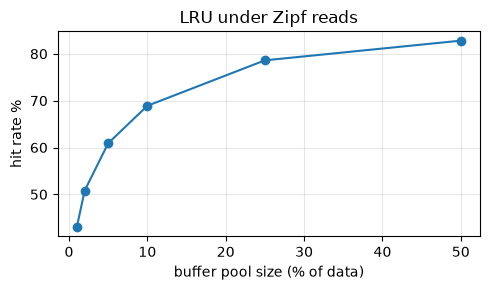

In [5]:
def hot_hit_rate_after_scan(use_ring):
    pool = LRUBufferPool(2_000)                          # 10% of the data
    for p in trace[:20_000]:
        pool.read(int(p))                                # warm up with hot traffic
    for p in range(N_PAGES):                             # one full scan of another big table (report query)
        pool.read(100_000 + p, use_ring=use_ring)
    pool.hits = pool.misses = 0
    for p in trace[20_000:22_000]:                       # the next 2,000 hot reads right after the scan
        pool.read(int(p))
    return round(100 * pool.hits / 2_000, 1)

print("hit rate of hot traffic right after a big scan")
print("  plain LRU (scan floods the pool):", hot_hit_rate_after_scan(False), "%")
print("  scan uses a ring buffer         :", hot_hit_rate_after_scan(True), "%")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(hit_df["pool size (% of data)"], hit_df["hit rate %"], marker="o")
ax.set_xlabel("buffer pool size (% of data)"); ax.set_ylabel("hit rate %"); ax.set_title("LRU under Zipf reads")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**What to check in PostgreSQL** (shown, needs a server): the buffer hit ratio per table, and which queries read the most pages.

```sql
-- Share of table page reads served from shared_buffers (aim high on OLTP; "high" depends on your workload)
SELECT relname, heap_blks_hit, heap_blks_read,
       round(100.0 * heap_blks_hit / nullif(heap_blks_hit + heap_blks_read, 0), 1) AS hit_pct
FROM pg_statio_user_tables ORDER BY heap_blks_read DESC LIMIT 10;

-- For one query: where did the pages come from?
EXPLAIN (ANALYZE, BUFFERS) SELECT * FROM orders WHERE user_id = 42;
--   Buffers: shared hit=12 read=3     <- 12 pages from the pool, 3 fetched from the OS
```

**Limits to keep in mind:** a low hit ratio usually means the working set does not fit in RAM, or a query reads far more pages than it should (missing index, see section 2.3). Raising memory is the expensive fix; reading fewer pages is the cheap one.

### 1.4 The plan cache and prepared statements

**What it is:** before running SQL, the database **parses** it, checks it, and **plans** it (picks indexes and join order). For a tiny query, planning can cost as much as running. A **prepared statement** is parsed once and run many times with different parameter values.

**Simple analogy:** a fill-in-the-blanks form. You design the form once, then just fill in a new name each time.

**How it works in PostgreSQL:** `PREPARE` (or the driver's protocol-level prepare) stores the parsed statement **for the current session only**. With the default `plan_cache_mode = auto`, the first five executions get a **custom plan** (planned for the actual values), then PostgreSQL compares a **generic plan** (one plan for all values) and keeps it if it is not much worse. Most drivers do this for you: psycopg 3 prepares a query automatically after it has run a few times on a connection (`prepare_threshold`), and asyncpg caches prepared statements per connection.

**When not to rely on it:** with PgBouncer in transaction mode, your next transaction may land on a different server connection that does not have your prepared statement (section 2.1). PgBouncer 1.21+ can track protocol-level prepared statements (`max_prepared_statements`); some hosted poolers cannot, and their docs tell you to switch the driver's cache off (for example `statement_cache_size=0` in asyncpg, or `prepare_threshold=None` in psycopg 3).

**Demo:** Python's `sqlite3` keeps a per-connection cache of compiled statements, keyed by the SQL text. A parameterized query has one SQL text, so it compiles once. Building the SQL with an f-string creates a new text every time, so every call is parsed again. (It is also how SQL injection happens.)

In [6]:
con = sqlite3.connect(SHOP_DB)
ids = [random.randint(1, 20_000) for _ in range(20_000)]

def lookup_parameterized():
    for uid in ids:
        con.execute("SELECT email, plan FROM users WHERE id = ?", (uid,)).fetchone()   # same text every time

def lookup_fstring():
    for uid in ids:
        con.execute(f"SELECT email, plan FROM users WHERE id = {uid}").fetchone()       # new text every time

_, ms_param = timed(lookup_parameterized)
_, ms_fstr = timed(lookup_fstring)
con.close()
print(f"parameterized (compiled once, reused): {ms_param:7.0f} ms")
print(f"f-string SQL  (compiled every time)  : {ms_fstr:7.0f} ms   ({ms_fstr / ms_param:.1f}x slower, and unsafe)")

parameterized (compiled once, reused):     179 ms
f-string SQL  (compiled every time)  :     433 ms   (2.4x slower, and unsafe)


### 1.5 Materialized views

**What it is:** a normal **view** is a saved query that runs every time you read it. A **materialized view** runs the query once and stores the result as a real table. Reads are fast; the data is a snapshot until you **refresh** it.

**Simple analogy:** a printed weekly sales report. Reading it is instant, but it does not show today's sales until someone prints a new one.

**How it works (PostgreSQL, shown):**

```sql
CREATE MATERIALIZED VIEW daily_revenue AS
SELECT created_at::date AS day, sum(amount_cents) AS revenue_cents, count(*) AS orders
FROM orders WHERE status = 'paid' GROUP BY 1;

CREATE UNIQUE INDEX ON daily_revenue (day);              -- needed for CONCURRENTLY

REFRESH MATERIALIZED VIEW daily_revenue;                 -- fast, but blocks readers while it runs
REFRESH MATERIALIZED VIEW CONCURRENTLY daily_revenue;    -- readers keep working; needs a unique index
```

| Refresh strategy | How | Good for | Watch out |
|---|---|---|---|
| Full refresh on a schedule | cron / `pg_cron` / cloud scheduler runs `REFRESH ... CONCURRENTLY` every N minutes | dashboards that may be minutes old | refresh cost grows with the base data |
| Refresh after a batch load | the ETL job refreshes at the end | nightly reports | readers see yesterday until it finishes |
| Incremental summary table | your own table updated by triggers or by the write path (`INSERT ... ON CONFLICT DO UPDATE`) | counters, leaderboards that must be fresh | more code; must stay correct under concurrency |
| No materialization | a good index plus a plain query | small data | nothing to refresh |

Only one `REFRESH` can run at a time per materialized view. The demo below fakes a materialized view in SQLite with `CREATE TABLE ... AS SELECT`, and shows both the speed-up and the staleness.

In [7]:
con = sqlite3.connect(SHOP_DB)
AGG = "SELECT created_at AS day, sum(amount_cents) AS revenue, count(*) AS n FROM orders WHERE status='paid' GROUP BY created_at"

def refresh_mv():
    con.execute("DROP TABLE IF EXISTS mv_daily_revenue")
    con.execute(f"CREATE TABLE mv_daily_revenue AS {AGG}")
    con.execute("CREATE UNIQUE INDEX mv_day ON mv_daily_revenue(day)")
    con.commit()

_, ms_refresh = timed(refresh_mv)
_, ms_raw = timed(lambda: con.execute(AGG).fetchall())
_, ms_mv = timed(lambda: con.execute("SELECT * FROM mv_daily_revenue").fetchall())
print(f"aggregate on raw orders: {ms_raw:6.1f} ms | read the materialized table: {ms_mv:6.2f} ms | refresh cost: {ms_refresh:6.1f} ms")

# Staleness: a new paid order arrives
con.execute("INSERT INTO orders(user_id, amount_cents, status, created_at, note) VALUES (1, 999999, 'paid', '2026-11-13', '')")
con.commit()
q = "SELECT revenue FROM {} WHERE day='2026-11-13'"
print("raw query sees new order :", con.execute(AGG.replace("GROUP BY", "AND created_at='2026-11-13' GROUP BY")).fetchone()[1])
print("materialized view (stale):", con.execute(q.format("mv_daily_revenue")).fetchone())
refresh_mv()
print("after refresh            :", con.execute(q.format("mv_daily_revenue")).fetchone()[0])
con.execute("DELETE FROM orders WHERE amount_cents = 999999"); con.commit(); con.close()

aggregate on raw orders:   85.2 ms | read the materialized table:   0.29 ms | refresh cost:  143.6 ms
raw query sees new order : 8695001
materialized view (stale): (7695002,)
after refresh            : 8695001


### 1.6 Application-level caching: cache-aside

**What it is:** **cache-aside** (also called lazy loading) means your code checks a cache (usually Redis) first, and on a miss reads the database and stores the result with a **TTL** (time to live). The patterns (cache-aside, read-through, write-through, write-behind), TTL jitter, stampede protection and eviction are all covered with runnable demos in [13_Databases/10 Redis and Caching](../13_Databases/10_redis_and_caching_for_ai_applications.ipynb). Here is the production shape of the code:

```python
# FastAPI + redis-py (shown, not executed)
import json, redis.asyncio as redis
r = redis.from_url(settings.redis_url)

async def get_user_profile(user_id: int) -> dict:
    key = f"v1:user:{user_id}:profile"                # versioned, namespaced key
    if (cached := await r.get(key)) is not None:
        return json.loads(cached)                     # hit
    row = await db.fetch_one("SELECT id, name, plan FROM users WHERE id = $1", user_id)
    await r.set(key, json.dumps(dict(row)), ex=300 + random.randint(0, 60))   # TTL + jitter
    return dict(row)
```

**Where it helps and where not:**

| Good fit | Poor fit |
|---|---|
| read-heavy data that many requests share (product catalog, user profile, LLM answers to repeated prompts) | data that must be exactly current (account balance, stock count at checkout) |
| expensive queries or third-party API calls | queries that are already fast with an index (the cache adds a network hop and a consistency problem) |
| data where a few seconds or minutes of staleness is fine | per-request unique data (nothing will be reused) |

Below is a tiny in-memory stand-in for Redis that we reuse in 1.9. It counts how many reads reach the database.

In [8]:
class TTLCache:
    """Tiny stand-in for Redis GET/SET with expiry. The clock is passed in so demos are deterministic."""
    def __init__(self):
        self.data = {}
    def get(self, key, now):
        item = self.data.get(key)
        if item and item[1] > now:
            return item[0]
        self.data.pop(key, None)
        return None
    def set(self, key, value, ttl, now):
        self.data[key] = (value, now + ttl)
    def delete(self, key):
        self.data.pop(key, None)

db_reads = Counter()
user_db = sqlite3.connect(":memory:", check_same_thread=False)
user_db.execute("CREATE TABLE users (id INTEGER PRIMARY KEY, name TEXT, plan TEXT)")
user_db.executemany("INSERT INTO users VALUES (?,?,?)", [(i, f"User {i}", "free") for i in range(1, 101)])

def db_get_user(uid):
    db_reads["users"] += 1
    return dict(zip(("id", "name", "plan"), user_db.execute("SELECT id, name, plan FROM users WHERE id=?", (uid,)).fetchone()))

cache = TTLCache()
def get_user_cached(uid, now, ttl=60):
    key = f"v1:user:{uid}"
    value = cache.get(key, now)
    if value is None:                                   # miss: read DB and fill the cache
        value = db_get_user(uid)
        cache.set(key, value, ttl, now)
    return value

for t in range(1000):                                   # 1000 requests for a few hot users
    get_user_cached(random.choice([1, 2, 3, 4, 5]), now=t * 0.1)
print("requests: 1000, database reads:", db_reads["users"])

requests: 1000, database reads: 10


### 1.7 ORM identity maps and caches

**What it is:** an **identity map** is a per-session dictionary inside the ORM: "row `users.id=42` is this Python object". SQLAlchemy's `Session` has one. If you load the same row twice in one session, you get the same object back, and `session.get(User, 42)` does not even send SQL the second time.

**Simple analogy:** a notepad on your desk during one meeting. It saves you asking twice in the same meeting, but you throw it away afterwards.

**How it bites in production:**
- It is **not** a shared cache. Each request should get its own short-lived session (one session per request is the normal FastAPI pattern via a dependency). A long-lived global session keeps old objects and shows stale data.
- SQLAlchemy expires objects on commit by default (`expire_on_commit=True`), so attributes reload on next access. Async code often sets `expire_on_commit=False` to avoid surprise lazy loads, and then must remember the objects can be stale.
- Lazy loading of relationships is the usual source of the N+1 problem (section 2.2).
- Django has no identity map, but a QuerySet caches its results once evaluated; reusing the same QuerySet object avoids a second query, building a new one does not.

```python
# SQLAlchemy 2.x (shown)
with Session(engine) as session:              # one session per request / unit of work
    a = session.get(User, 42)                 # SELECT ... WHERE id = 42
    b = session.get(User, 42)                 # no SQL: found in the identity map
    assert a is b
    session.execute(select(User).where(User.id == 42).execution_options(populate_existing=True))  # force refresh
```

**Best practice:** treat ORM caching as a correctness feature (one object per row per unit of work), not a performance layer. For cross-request caching use Redis with explicit keys and TTLs.

### 1.8 HTTP and CDN caching for API responses: ETag and 304

**What it is:** HTTP has caching built in. The server labels a response with an **`ETag`** (a fingerprint of the content) and a **`Cache-Control`** header (who may cache it, and for how long). Next time, the client sends `If-None-Match: <etag>`. If nothing changed, the server answers **`304 Not Modified`** with an empty body.

**Simple analogy:** "Is the menu still the same as the one I have (version 7)?" "Yes." No need to hand over a new menu.

**Which `Cache-Control` for an API:**

| Response | Header | Effect |
|---|---|---|
| public, same for everyone (pricing page data, model list) | `public, max-age=60, s-maxage=300, stale-while-revalidate=30` | browsers 60 s, CDN 5 min, may serve slightly stale while refreshing |
| per-user data | `private, no-cache` + `ETag` | only the browser may store it, and must revalidate each time (cheap with 304) |
| secrets, tokens, one-time data | `no-store` | never stored anywhere |
| LLM streaming responses | `no-store` (or `no-cache`) | never cached by proxies |

Never let a CDN cache a response that depends on the `Authorization` header or a cookie unless the cache key includes it. Most CDNs skip caching when they see those, but check. The demo shows the server side of `ETag`/`304`.

In [9]:
def make_etag(body: bytes) -> str:
    return '"' + hashlib.sha256(body).hexdigest()[:16] + '"'      # strong ETag: quoted string

def get_models_endpoint(request_headers, models):
    body = json.dumps({"models": models}, sort_keys=True).encode()
    etag = make_etag(body)
    headers = {"ETag": etag, "Cache-Control": "public, max-age=60, s-maxage=300"}
    if request_headers.get("If-None-Match") == etag:
        return 304, headers, b""                                      # nothing changed: empty body
    return 200, headers, body

models = [{"id": f"model-{i}", "context": 128_000} for i in range(50)]
s1, h1, b1 = get_models_endpoint({}, models)
s2, h2, b2 = get_models_endpoint({"If-None-Match": h1["ETag"]}, models)
models.append({"id": "model-new", "context": 1_000_000})
s3, h3, b3 = get_models_endpoint({"If-None-Match": h1["ETag"]}, models)
print(f"first request : {s1}, {len(b1)} bytes, ETag {h1['ETag']}")
print(f"revalidate    : {s2}, {len(b2)} bytes")
print(f"after a change: {s3}, {len(b3)} bytes, new ETag {h3['ETag']}")

first request : 200, 1952 bytes, ETag "74cb9cb88374150e"
revalidate    : 304, 0 bytes
after a change: 200, 1993 bytes, new ETag "4dac4ab0f2fb7bac"


### 1.9 The hard part: invalidation, consistency and stale reads

**What it is:** a **stale read** is when a reader sees an old value after a newer one was written. Every cache layer can cause one. "There are only two hard things in computer science: cache invalidation and naming things" is a famous joke for a reason.

**How it happens:** cache-aside fills the cache on read. If a write updates the database but nobody removes the cached copy, readers keep getting the old value until the TTL expires.

**Fixes, from simplest to strongest:**

| Fix | How | Staleness left | Cost |
|---|---|---|---|
| Short TTL | expire after N seconds | up to N seconds | more misses |
| Delete on write | after the DB commit, `DEL` the key | a small race window (see below) | must find every write path |
| Versioned keys | key contains a version (`user:42:v17`) that bumps on write | none for readers that read the new version | extra version lookup or a version in the token |
| Write-through | write path updates DB and cache together | small | write path slower |
| Bypass for the writer | after a user writes, read their own data from the database (or the primary) for a few seconds | none for that user | a little more DB load |
| Change data capture | a consumer reads the database change stream and invalidates keys | small, eventually consistent | more infrastructure |

There is a classic race even with delete-on-write: a slow reader fetched the old row before the write, and puts it into the cache after the delete. The runnable timeline and fixes (short TTL as a safety net, delayed double delete, versioned values) are in [13_Databases/10, section 2.6](../13_Databases/10_redis_and_caching_for_ai_applications.ipynb). The demo below shows the basic stale read and two fixes.

In [10]:
def scenario(fix):
    cache.data.clear()
    user_db.execute("UPDATE users SET plan='free' WHERE id=7")
    log = []
    log.append(("t=0  read", get_user_cached(7, now=0)["plan"]))       # fills cache with plan=free
    # t=1: user upgrades to pro
    user_db.execute("UPDATE users SET plan='pro' WHERE id=7")
    if fix == "delete on write":
        cache.delete("v1:user:7")
    log.append(("t=2  read", get_user_cached(7, now=2)["plan"]))
    log.append(("t=61 read", get_user_cached(7, now=61)["plan"]))      # after TTL=60
    return {"fix": fix, **dict(log)}

def scenario_writer_bypass():
    cache.data.clear()
    user_db.execute("UPDATE users SET plan='free' WHERE id=7")
    get_user_cached(7, now=0)
    user_db.execute("UPDATE users SET plan='pro' WHERE id=7")
    recent_writers = {7: 1}                                             # user 7 wrote at t=1
    def read(uid, now):
        if now - recent_writers.get(uid, -1e9) < 10:                    # wrote in the last 10 s: skip cache
            return db_get_user(uid)
        return get_user_cached(uid, now)
    return {"fix": "writer reads DB for 10 s", "t=0  read": "free", "t=2  read": read(7, 2)["plan"],
            "t=61 read": read(7, 61)["plan"]}

print(pd.DataFrame([scenario("none (TTL only)"), scenario("delete on write"), scenario_writer_bypass()]).to_string(index=False))
print("\nNote: with the writer-bypass fix, OTHER users still see 'free' from the cache until the TTL ends.")

                     fix t=0  read t=2  read t=61 read
         none (TTL only)      free      free       pro
         delete on write      free       pro       pro
writer reads DB for 10 s      free       pro       pro

Note: with the writer-bypass fix, OTHER users still see 'free' from the cache until the TTL ends.


> **Best practices: caching**
> - Fix the query first (index, fewer rows, no N+1). Cache second. A cache in front of a slow query hides the problem until the cache is cold.
> - Give every cached key a TTL, even when you also invalidate on write. The TTL is your safety net for missed invalidations.
> - Namespace and version keys (`v2:user:42`), so a format change or a bad deploy can be fixed by bumping the version.
> - Decide per data type how stale is acceptable, and write it down. Never cache balances, permissions or anything a security check depends on without a very short TTL and invalidation.
> - Use `ETag` + `private, no-cache` for per-user GETs, `public, s-maxage` only for truly public data, `no-store` for secrets and streams.
>
> **Living within limits:** `shared_buffers` about 25% of RAM to start, leave the rest for the OS cache and per-connection memory (`work_mem` is per sort/hash operation, so it multiplies). Redis memory is finite: set `maxmemory` and an eviction policy (see 13/10). In serverless functions, in-process caches are lost on every cold start, so use a shared cache.

## 2. Database performance in production

Most slow APIs are slow because of the database, and most database problems in a young product are one of five things: too many connections, N+1 queries, a missing index, deep `OFFSET` pagination, or long transactions holding locks. This section covers those first, then the operational topics (replicas, partitioning, migrations, backups).

### 2.1 Connection pooling

**What it is:** opening a database connection is expensive, and each open connection costs the server memory. A **connection pool** keeps a small number of connections open and lends them to requests, like a library lending a few copies of a popular book.

**Why each connection costs so much (PostgreSQL):** PostgreSQL uses one operating-system **process per connection**. Each one has its own private memory (catalog caches, plus `work_mem`, default 4 MB, for *each* sort or hash step of a query, so one complex query can use several times that). Opening one means a TCP handshake, usually TLS, authentication and starting a process. And `max_connections` defaults to typically **100**, with 3 reserved for superusers.

More connections is not more speed. The PostgreSQL wiki suggests the number of *active* connections for best throughput is near `(core_count * 2) + effective_spindle_count` (spindles are 0 when data is cached), because beyond that the extra queries only fight for CPU, locks and memory.

**How pooling works:**

```mermaid
flowchart LR
    subgraph App["API instances (each has an app-side pool)"]
      A1["instance 1<br/>pool_size=5"]
      A2["instance 2<br/>pool_size=5"]
      F["serverless functions<br/>hundreds of short-lived clients"]
    end
    A1 --> PB["PgBouncer / managed pooler<br/>thousands of client connections"]
    A2 --> PB
    F --> PB
    PB -->|"default_pool_size=20 per user+db"| PG[("PostgreSQL<br/>max_connections=100")]
```

There are two levels:
1. **App-side pool** (inside your process): SQLAlchemy, asyncpg and psycopg pools. It removes connect cost per request.
2. **External pooler** (a separate service in front of the database): PgBouncer, Pgpool-II, or a managed one (AWS RDS Proxy, the built-in PgBouncer of Azure Database for PostgreSQL flexible server, Google Cloud SQL managed connection pooling, Neon's and Supabase's poolers). It lets many app instances share few real connections.

**PgBouncer pooling modes** (from the PgBouncer docs):

| Mode | A server connection is given to a client... | Supports | Use when |
|---|---|---|---|
| **session** (default) | until the client disconnects | every PostgreSQL feature | long-lived app servers with their own pool; migrations |
| **transaction** | only for the length of one transaction | most things, but **not**: `SET`/`RESET` session settings, `LISTEN`, `WITH HOLD` cursors, SQL-level `PREPARE`, session advisory locks, `LOAD`, temp tables that outlive a transaction. Protocol-level prepared statements work if `max_prepared_statements` is non-zero (PgBouncer 1.21+) | many clients, short transactions: serverless, many small instances |
| **statement** | for one statement; multi-statement transactions refused | very little | rare (PL/Proxy setups) |

Useful PgBouncer settings: `max_client_conn` (client side, default 100), `default_pool_size` (server connections per user+database pair, default 20), `query_wait_timeout` (how long a client may wait for a server connection, default 120 s), `server_idle_timeout` (default 600 s).

**App-side pool settings (SQLAlchemy 2.x, shown):**

```python
engine = create_async_engine(
    settings.database_url,
    pool_size=5,          # connections kept open per process (SQLAlchemy default 5)
    max_overflow=10,      # extra connections allowed under bursts (default 10)
    pool_timeout=5,       # seconds to wait for a free connection before erroring (default 30; lower fails fast)
    pool_recycle=1800,    # replace connections older than 30 min (load balancers and poolers drop idle ones)
    pool_pre_ping=True,   # test a connection before use; avoids "server closed the connection" after failover
)
# Behind PgBouncer in transaction mode, many teams let PgBouncer do the pooling:
# engine = create_async_engine(url, poolclass=NullPool,
#                              connect_args={"statement_cache_size": 0})   # asyncpg: no cached prepared statements
```

**Serverless connection storms:** each function instance opens its own connection. A traffic spike starts hundreds of instances, each connects, and the database hits `max_connections` ("FATAL: sorry, too many clients already"), so *everything* fails, including healthy servers. Fixes:
- Use the provider's **pooled connection string**. On Neon you add `-pooler` to the endpoint host name (PgBouncer in transaction mode, up to 10,000 client connections). On Supabase the shared pooler uses port **6543** for transaction mode (port 5432 for session mode and direct). On AWS use RDS Proxy.
- Use the **direct** (unpooled) connection for migrations, `pg_dump`/`pg_restore` and anything that needs session features.
- Cap function concurrency, keep one connection per instance, and close it on shutdown.
- Consider an HTTP-based database driver (several serverless Postgres vendors offer one) for edge runtimes that cannot keep TCP sockets.

**The budget rule:** the sum over every client of its maximum connections must stay below `max_connections` minus reserved ones. The cell below checks a plan.

In [11]:
def connection_budget(max_connections=100, reserved=3, admin_headroom=5, **clients):
    """clients: name=(instances, pool_size, max_overflow). Returns a small report."""
    usable = max_connections - reserved - admin_headroom
    rows, total = [], 0
    for name, (instances, pool_size, overflow) in clients.items():
        peak = instances * (pool_size + overflow)
        total += peak
        rows.append({"client": name, "instances": instances, "per instance": pool_size + overflow, "peak": peak})
    df = pd.DataFrame(rows)
    verdict = "OK" if total <= usable else f"OVER by {total - usable}: lower pools or add a pooler"
    return df, f"peak {total} vs usable {usable} -> {verdict}"

df, verdict = connection_budget(api=(4, 5, 10), worker=(2, 5, 0), cron=(1, 2, 0))
print(df.to_string(index=False)); print(verdict, "\n")
df, verdict = connection_budget(api=(4, 5, 10), lambda_fn=(300, 1, 0))
print(df.to_string(index=False)); print(verdict)

client  instances  per instance  peak
   api          4            15    60
worker          2             5    10
  cron          1             2     2
peak 72 vs usable 92 -> OK 

   client  instances  per instance  peak
      api          4            15    60
lambda_fn        300             1   300
peak 360 vs usable 92 -> OVER by 268: lower pools or add a pooler


**Simulation: throughput vs pool size.** 100 app threads hammer a database with 4 CPU cores. The pool size limits how many queries are active in the database at once; the other requests wait in the pool's queue. When more queries are active than there are cores, each runs slower, and a small contention penalty (locks, context switches, cache misses) makes the total *throughput* drop too. This is a simple model with illustrative numbers, but the shape matches what the PostgreSQL wiki describes.

 pool size  throughput req/s  p50 ms  p95 ms
         1               194     498     552
         2               374     263     300
         4               773     128     150
         8               707     139     168
        16               578     166     227
        32               425     208     377
        64               287     256     706
       100               209     278    1162


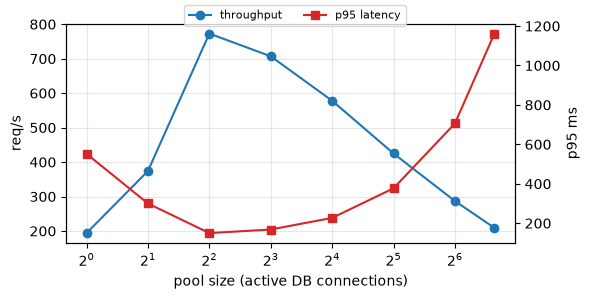

In [12]:
def simulate_pool(pool_size, clients=100, cores=4, work_ms=5.0, contention=0.03, sim_ms=3000, dt=0.5, seed=1):
    """Time-stepped model. Each request needs ~work_ms of CPU. Latency = wait for a connection + run time."""
    rng = np.random.default_rng(seed)
    waiting = deque((c, 0.0) for c in range(clients))     # (client, time it started waiting)
    active = {}                                            # client -> [remaining work ms, start time]
    latencies = []
    for step in range(int(sim_ms / dt)):
        now = step * dt
        while waiting and len(active) < pool_size:          # hand out free connections
            c, t0 = waiting.popleft()
            active[c] = [rng.exponential(work_ms), t0]
        k = len(active)
        if k == 0:
            continue
        speed = min(1.0, cores / k) / (1 + contention * max(0, k - cores))   # share CPU, pay for contention
        finished = []
        for c, job in active.items():
            job[0] -= speed * dt
            if job[0] <= 0:
                finished.append(c)
        for c in finished:
            latencies.append(now + dt - active.pop(c)[1])
            waiting.append((c, now + dt))                   # the client immediately sends its next request
    lat = np.array(latencies)
    return {"pool size": pool_size, "throughput req/s": round(len(lat) / (sim_ms / 1000)),
            "p50 ms": round(np.percentile(lat, 50)), "p95 ms": round(np.percentile(lat, 95))}

pool_df = pd.DataFrame([simulate_pool(p) for p in [1, 2, 4, 8, 16, 32, 64, 100]])
print(pool_df.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(6, 3))
ax1.plot(pool_df["pool size"], pool_df["throughput req/s"], marker="o", label="throughput")
ax1.set_xscale("log", base=2); ax1.set_xlabel("pool size (active DB connections)"); ax1.set_ylabel("req/s")
ax2 = ax1.twinx(); ax2.plot(pool_df["pool size"], pool_df["p95 ms"], marker="s", color="tab:red", label="p95 latency")
ax2.set_ylabel("p95 ms")
fig.legend(loc="upper center", ncol=2, fontsize=8); ax1.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Reading the result:** throughput peaks near the number of cores and p95 latency is lowest around there. With a huge pool, every request is "connected" but all of them crawl, and tail latency explodes. Requests waiting in a small pool's queue are cheap; queries fighting inside the database are not. This is why a pool of 5-20 server connections often serves thousands of client connections.

Two things to add in a real service: a **pool timeout** (fail fast with 503 instead of queueing forever) and a **statement timeout** in the database (section 5.4).

### 2.2 The N+1 query problem

**What it is:** you run **1** query to get a list, then **N** more queries, one per item, to get related data. With 50 items that is 51 round trips. ORMs make this easy to do by accident through **lazy loading** (`post.author` quietly runs a query).

**Simple analogy:** going to the shop 50 times to buy 50 items, instead of once with a list.

**Fixes:**
1. **JOIN**: one query returns posts with their author columns.
2. **Batched `IN`**: one query for posts, one query `WHERE id IN (...)` for all their authors (this is what SQLAlchemy `selectinload` does).
3. **DataLoader**: collect all the keys requested during one "tick", then load them with one batched query. Common in GraphQL servers, where each field resolver asks for its own data.

**Demo:** 200 authors, 2,000 posts, list the latest 100 posts with author names. SQLite runs inside our process, so each query is very cheap; in production each query also pays a network **round trip** (often around a millisecond within one region, much more across regions). We count queries and add an illustrative 1 ms per round trip.

In [13]:
blog = sqlite3.connect(":memory:")
blog.executescript("""
CREATE TABLE authors (id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE posts (id INTEGER PRIMARY KEY, author_id INTEGER, title TEXT, created_at INTEGER);
""")
blog.executemany("INSERT INTO authors VALUES (?,?)", [(i, f"Author {i}") for i in range(1, 201)])
blog.executemany("INSERT INTO posts VALUES (?,?,?,?)",
                 [(i, random.randint(1, 200), f"Post {i}", i) for i in range(1, 2001)])

queries = []
blog.set_trace_callback(queries.append)          # record every SQL statement SQLite runs

def n_plus_one():
    posts = blog.execute("SELECT id, author_id, title FROM posts ORDER BY created_at DESC LIMIT 100").fetchall()
    return [(t, blog.execute("SELECT name FROM authors WHERE id=?", (a,)).fetchone()[0]) for _, a, t in posts]

def join():
    return blog.execute("""SELECT p.title, a.name FROM posts p JOIN authors a ON a.id = p.author_id
                           ORDER BY p.created_at DESC LIMIT 100""").fetchall()

def batched_in():
    posts = blog.execute("SELECT id, author_id, title FROM posts ORDER BY created_at DESC LIMIT 100").fetchall()
    ids = sorted({a for _, a, _ in posts})
    names = dict(blog.execute(f"SELECT id, name FROM authors WHERE id IN ({','.join('?' * len(ids))})", ids))
    return [(t, names[a]) for _, a, t in posts]

class AuthorLoader:
    """Minimal DataLoader: .load() returns a placeholder; .dispatch() runs ONE query for all queued keys."""
    def __init__(self):
        self.queue, self.cache = [], {}
    def load(self, key):
        if key not in self.cache:
            self.queue.append(key)
        return lambda: self.cache[key]
    def dispatch(self):
        keys = sorted(set(self.queue)); self.queue.clear()
        if keys:
            self.cache.update(blog.execute(f"SELECT id, name FROM authors WHERE id IN ({','.join('?' * len(keys))})", keys))

def dataloader():
    loader = AuthorLoader()
    posts = blog.execute("SELECT id, author_id, title FROM posts ORDER BY created_at DESC LIMIT 100").fetchall()
    pending = [(t, loader.load(a)) for _, a, t in posts]   # every "resolver" asks for its author
    loader.dispatch()                                      # one batched query at the end of the tick
    return [(t, get()) for t, get in pending]

rows = []
for fn in [n_plus_one, join, batched_in, dataloader]:
    queries.clear()
    result, ms = timed(fn)
    rows.append({"strategy": fn.__name__, "queries": len(queries), "local ms": round(ms, 2),
                 "est. ms with 1 ms RTT": round(ms + len(queries) * 1.0, 1), "rows": len(result)})
blog.set_trace_callback(None)
print(pd.DataFrame(rows).to_string(index=False))

  strategy  queries  local ms  est. ms with 1 ms RTT  rows
n_plus_one      101      1.80                  102.8   100
      join        1      1.49                    2.5   100
batched_in        2      1.55                    3.5   100
dataloader        2      1.56                    3.6   100


**Fixing N+1 in an ORM (SQLAlchemy 2.x, shown):**

```python
from sqlalchemy.orm import selectinload, joinedload, raiseload

stmt = select(Post).options(selectinload(Post.author)).order_by(Post.created_at.desc()).limit(100)  # 2 queries
stmt = select(Post).options(joinedload(Post.author)).limit(100)        # 1 query with a JOIN (good for many-to-one)
stmt = select(Post).options(raiseload("*"))                             # any lazy load raises: catches N+1 in tests
```

Django: `select_related("author")` (JOIN) and `prefetch_related("tags")` (batched `IN`). **Find it** by counting queries per request in tests (assert "this endpoint runs at most 3 queries"), or by looking for one statement with a very high `calls` count in `pg_stat_statements` (2.4). APM tools also flag N+1 patterns.

### 2.3 Indexes, recap with EXPLAIN

**What it is:** an **index** is a sorted lookup structure (usually a B-tree) that lets the database jump to matching rows instead of reading the whole table. How B-tree, hash, GIN, GiST and BRIN indexes work is in [13_Databases/09](../13_Databases/09_indexing_patterns_database_and_vector_side_by_side.ipynb); how the planner chooses is in [13_Databases/00/08](../13_Databases/00_dbms_fundamentals/08_query_processing_and_optimization.ipynb). In production, the skill is reading `EXPLAIN`.

**Demo:** "my orders, newest first" without and with a composite index on `(user_id, created_at)`. SQLite's `EXPLAIN QUERY PLAN` says `SCAN` (read everything) or `SEARCH ... USING INDEX` (jump straight there).

In [14]:
con = sqlite3.connect(SHOP_DB)
MY_ORDERS = "SELECT id, amount_cents, created_at FROM orders WHERE user_id = ? ORDER BY created_at DESC LIMIT 20"

def plan(sql, params=()):
    return " | ".join(r[3] for r in con.execute("EXPLAIN QUERY PLAN " + sql, params))

def avg_ms(sql, params, n=50):
    _, ms = timed(lambda: [con.execute(sql, params).fetchall() for _ in range(n)])
    return ms / n

con.execute("DROP INDEX IF EXISTS idx_orders_user_created")
print("before:", plan(MY_ORDERS, (42,)), f"-> {avg_ms(MY_ORDERS, (42,)):.2f} ms/query")
con.execute("CREATE INDEX idx_orders_user_created ON orders(user_id, created_at)")
print("after :", plan(MY_ORDERS, (42,)), f"-> {avg_ms(MY_ORDERS, (42,)):.3f} ms/query")
con.execute("DROP INDEX idx_orders_user_created"); con.commit(); con.close()   # section 6 needs it missing

before: SCAN orders | USE TEMP B-TREE FOR ORDER BY -> 22.94 ms/query


after : SEARCH orders USING INDEX idx_orders_user_created (user_id=?) -> 0.031 ms/query


**Reading a PostgreSQL plan (shown; the output is illustrative):**

```sql
EXPLAIN (ANALYZE, BUFFERS) SELECT id FROM orders WHERE user_id = 42 ORDER BY created_at DESC LIMIT 20;
```
```text
Limit  (actual time=95.1..95.2 rows=20 loops=1)
  ->  Sort  (actual time=95.1..95.1 rows=20 loops=1)
        Sort Method: top-N heapsort  Memory: 26kB
        ->  Seq Scan on orders  (cost=0.00..9821.00 rows=15 width=12) (actual time=0.03..95.0 rows=14 loops=1)
              Filter: (user_id = 42)
              Rows Removed by Filter: 299986
              Buffers: shared hit=2100 read=3721
```

What to look for: **`Seq Scan` on a big table with a selective filter** (missing index); **`Rows Removed by Filter`** much larger than rows returned; **estimated rows far from actual rows** (stale statistics: run `ANALYZE`); `Sort Method: external merge` (sort spilled to disk: query needs more `work_mem` or an index that gives the order); many `read=` buffers (cold data). `ANALYZE` actually runs the query, so wrap writes in `BEGIN; ... ROLLBACK;`.

**Index best practices:** index the columns in your `WHERE` and `ORDER BY` (equality columns first, then the range/sort column); every index slows writes and uses memory, so drop unused ones (`pg_stat_user_indexes.idx_scan = 0`); build them on live tables with `CREATE INDEX CONCURRENTLY`.

### 2.4 Slow-query logging and pg_stat_statements

**What it is:** two built-in ways to find slow SQL.
- **Slow-query log:** `log_min_duration_statement = '250ms'` logs every statement that takes at least 250 ms (`-1`, the default, turns it off; `0` logs everything). `log_lock_waits = on` logs sessions that waited longer than `deadlock_timeout` for a lock. The `auto_explain` module can also log the plan of slow statements.
- **`pg_stat_statements`:** an extension that groups statements by their shape (literal values removed) and keeps totals: `calls`, `total_exec_time`, `mean_exec_time`, `rows`, `shared_blks_hit`, `shared_blks_read`.

**Simple analogy:** the slow log is a speed camera (catches each very slow car). `pg_stat_statements` is a traffic survey (shows which road carries the most total traffic). Many fast queries can cost more in total than one slow one, which is exactly the N+1 signature.

```sql
-- postgresql.conf (needs a restart):  shared_preload_libraries = 'pg_stat_statements'
--                                     compute_query_id = auto      (the default)
CREATE EXTENSION pg_stat_statements;

SELECT query, calls, round(total_exec_time) AS total_ms, round(mean_exec_time, 2) AS mean_ms, rows,
       round(100.0 * shared_blks_hit / nullif(shared_blks_hit + shared_blks_read, 0), 1) AS hit_pct
FROM pg_stat_statements ORDER BY total_exec_time DESC LIMIT 10;
```

Managed databases expose the same data in their consoles (for example Amazon RDS Performance Insights / CloudWatch Database Insights, Cloud SQL Query Insights, Azure Query Store). **Demo:** a tiny version of `pg_stat_statements` in Python. It normalizes SQL by replacing literals with `?`, times each call, and logs the slow ones.

In [15]:
class StatStatements:
    def __init__(self, slow_ms=5.0):
        self.stats = defaultdict(lambda: {"calls": 0, "total_ms": 0.0, "max_ms": 0.0})
        self.slow_ms, self.slow_log = slow_ms, []

    @staticmethod
    def normalize(sql):
        sql = re.sub(r"'[^']*'", "?", sql)              # string literals
        sql = re.sub(r"\b\d+\b", "?", sql)              # numbers
        return re.sub(r"\s+", " ", sql).strip()

    def execute(self, con, sql, params=()):
        t0 = time.perf_counter()
        rows = con.execute(sql, params).fetchall()
        ms = (time.perf_counter() - t0) * 1000
        s = self.stats[self.normalize(sql)]
        s["calls"] += 1; s["total_ms"] += ms; s["max_ms"] = max(s["max_ms"], ms)
        if ms >= self.slow_ms:
            self.slow_log.append(f"duration: {ms:.1f} ms  statement: {sql[:70]}")
        return rows

    def top(self, n=5):
        df = pd.DataFrame([{"query": q[:60], **v} for q, v in self.stats.items()])
        df["mean_ms"] = df.total_ms / df.calls
        return df.sort_values("total_ms", ascending=False).head(n).round(3)

pgss = StatStatements(slow_ms=5.0)
con = sqlite3.connect(SHOP_DB)
for _ in range(3):                                     # a "report" endpoint: one slow full scan
    pgss.execute(con, "SELECT status, sum(amount_cents) FROM orders GROUP BY status")
for uid in range(1, 801):                              # an N+1 endpoint: many tiny queries
    pgss.execute(con, f"SELECT email FROM users WHERE id = {uid}")
con.close()
print(pgss.top().to_string(index=False))
print("\nslow log:"); print("\n".join(pgss.slow_log[:3]))

                                                       query  calls  total_ms  max_ms  mean_ms
SELECT status, sum(amount_cents) FROM orders GROUP BY status      3   501.771 186.630  167.257
                        SELECT email FROM users WHERE id = ?    800    16.547   0.069    0.021

slow log:
duration: 151.7 ms  statement: SELECT status, sum(amount_cents) FROM orders GROUP BY status
duration: 163.5 ms  statement: SELECT status, sum(amount_cents) FROM orders GROUP BY status
duration: 186.6 ms  statement: SELECT status, sum(amount_cents) FROM orders GROUP BY status


### 2.5 Keyset vs offset pagination

**What it is:** **offset pagination** (`LIMIT 50 OFFSET 10000`) makes the database find and *throw away* the first 10,000 rows on every request, so deep pages get slower and slower. **Keyset pagination** (also called cursor or seek pagination) remembers the last row you saw and asks for rows after it: `WHERE id < :last_id ORDER BY id DESC LIMIT 50`. With an index, every page costs the same.

**Simple analogy:** offset is "skip the first 200 pages of the book, then read 1 page", counting pages every time. Keyset is "open the book at my bookmark".

Offset also gives wrong results when rows are inserted or deleted between requests: items shift, so users see duplicates or miss items. Keyset does not have this problem.

| | Offset | Keyset |
|---|---|---|
| Jump to page 37 | yes | no (only next/previous) |
| Cost of deep pages | grows with the offset | constant with an index |
| Stable under inserts | no | yes |
| Good for | small admin tables, "page 1 of 5" UIs | feeds, APIs, infinite scroll, exports |

For a non-unique sort column, add a tie-breaker: `ORDER BY created_at DESC, id DESC` and `WHERE (created_at, id) < (:c, :id)` (row comparison works in PostgreSQL).

 rows skipped  OFFSET ms  keyset ms
            0       0.43      0.118
        10000       0.99      0.093
        50000       3.33      0.086
       100000       8.14      0.103
       200000      13.92      0.063
       290000      16.68      0.063


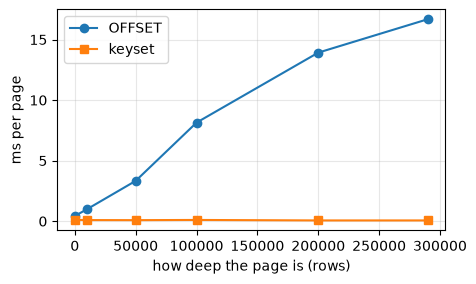

In [16]:
con = sqlite3.connect(SHOP_DB)
rows = []
for page_start in [0, 10_000, 50_000, 100_000, 200_000, 290_000]:
    _, ms_off = timed(lambda: con.execute("SELECT id, amount_cents FROM orders ORDER BY id LIMIT 50 OFFSET ?",
                                          (page_start,)).fetchall())
    last_id = page_start                     # in a real API this comes from the previous page's cursor
    _, ms_key = timed(lambda: con.execute("SELECT id, amount_cents FROM orders WHERE id > ? ORDER BY id LIMIT 50",
                                          (last_id,)).fetchall())
    rows.append({"rows skipped": page_start, "OFFSET ms": round(ms_off, 2), "keyset ms": round(ms_key, 3)})
con.close()
page_df = pd.DataFrame(rows)
print(page_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(page_df["rows skipped"], page_df["OFFSET ms"], marker="o", label="OFFSET")
ax.plot(page_df["rows skipped"], page_df["keyset ms"], marker="s", label="keyset")
ax.set_xlabel("how deep the page is (rows)"); ax.set_ylabel("ms per page"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 2.6 Batching writes and COPY

**What it is:** every committed transaction waits for the write-ahead log to be flushed to durable storage (an `fsync`). Inserting 10,000 rows in 10,000 separate transactions pays that 10,000 times. Batching many rows into one transaction, or one multi-row statement, pays it once. For bulk loads, PostgreSQL's **`COPY`** streams rows in a compact format and is the fastest path.

**Demo:** 100 rows with one commit each (with `fsync` like a real database) vs 20,000 rows in one transaction.

In [17]:
path = os.path.join(WORKDIR, "events.db")
con = sqlite3.connect(path, isolation_level=None)        # autocommit mode: each statement is its own transaction
con.execute("CREATE TABLE events (id INTEGER PRIMARY KEY, kind TEXT, payload TEXT)")

_, ms_each = timed(lambda: [con.execute("INSERT INTO events(kind, payload) VALUES (?, ?)", ("click", "{}")) for _ in range(100)])

def one_transaction(n=20_000):
    con.execute("BEGIN")
    con.executemany("INSERT INTO events(kind, payload) VALUES (?, ?)", [("click", "{}")] * n)
    con.execute("COMMIT")
_, ms_batch = timed(one_transaction)
con.close()
print(f"one commit per row : {ms_each / 100:.3f} ms per row")
print(f"one transaction    : {ms_batch / 20_000:.5f} ms per row  ({(ms_each / 100) / (ms_batch / 20_000):.0f}x faster)")

one commit per row : 14.359 ms per row
one transaction    : 0.00245 ms per row  (5851x faster)


**PostgreSQL bulk-write options (shown):**

```python
# psycopg 3: COPY is the fastest way to load many rows
with conn.cursor() as cur:
    with cur.copy("COPY events (kind, payload) FROM STDIN") as copy:
        for row in rows:
            copy.write_row(row)

# Multi-row INSERT for medium batches (also works with ON CONFLICT for upserts)
cur.executemany("INSERT INTO events (kind, payload) VALUES (%s, %s)", rows)   # psycopg 3 pipelines this
# SQLAlchemy 2.x: session.execute(insert(Event), list_of_dicts) uses "insertmanyvalues" batching
```

**Best practices:** batch in chunks (for example 1,000-10,000 rows) so one failure does not roll back an hour of work and locks are not held too long; for very large loads, consider creating secondary indexes after the load; use `ON CONFLICT DO NOTHING / DO UPDATE` to make reloads idempotent.

### 2.7 Transactions and isolation pitfalls

**What it is:** a **transaction** groups statements so they all succeed or all fail. The **isolation level** decides what concurrent transactions can see of each other. PostgreSQL's default is **Read Committed**: each statement sees data committed before *that statement* started. (Read Uncommitted behaves like Read Committed in PostgreSQL.) The theory is in [13_Databases/00/05](../13_Databases/00_dbms_fundamentals/05_transactions_and_concurrency_control.ipynb). In practice, the bug you will hit is the **lost update**.

**Lost update, step by step:** two requests withdraw from the same wallet (balance 100).
1. A reads balance = 100. 2. B reads balance = 100. 3. A writes 100 - 30 = 70. 4. B writes 100 - 50 = 50.
Final balance 50; A's withdrawal is lost. Read Committed does not prevent this, because each statement is fine on its own.

**Fixes:**

| Fix | SQL | When |
|---|---|---|
| Atomic update | `UPDATE wallets SET balance = balance - 30 WHERE id = 1 AND balance >= 30` | simple arithmetic; best default |
| Pessimistic lock | `SELECT ... FOR UPDATE` inside the transaction, then update | complex logic, high contention, short transactions |
| Optimistic lock | `UPDATE ... SET ..., version = version + 1 WHERE id = 1 AND version = :v`; 0 rows means someone else won: reload and retry | low contention, user edits, HTTP APIs (pairs with `ETag`/`If-Match`, section 3.9) |
| Stronger isolation | `REPEATABLE READ` or `SERIALIZABLE` | the database detects conflicts and aborts one transaction with SQLSTATE `40001`; you **must** retry the whole transaction |

`FOR UPDATE NOWAIT` errors instead of waiting; `FOR UPDATE SKIP LOCKED` skips locked rows, which is how Postgres-backed job queues let many workers claim different jobs (section 4). The demo uses two SQLite connections with a fixed interleaving.

In [18]:
wallet_path = os.path.join(WORKDIR, "wallet.db")
setup = sqlite3.connect(wallet_path, isolation_level=None)
setup.execute("CREATE TABLE IF NOT EXISTS wallets (id INTEGER PRIMARY KEY, balance INTEGER, version INTEGER)")

def reset():
    setup.execute("DELETE FROM wallets"); setup.execute("INSERT INTO wallets VALUES (1, 100, 1)")

a = sqlite3.connect(wallet_path, isolation_level=None)
b = sqlite3.connect(wallet_path, isolation_level=None)
balance = lambda: setup.execute("SELECT balance FROM wallets WHERE id=1").fetchone()[0]

# 1) read-modify-write in application code: lost update
reset()
bal_a = a.execute("SELECT balance FROM wallets WHERE id=1").fetchone()[0]
bal_b = b.execute("SELECT balance FROM wallets WHERE id=1").fetchone()[0]
a.execute("UPDATE wallets SET balance=? WHERE id=1", (bal_a - 30,))
b.execute("UPDATE wallets SET balance=? WHERE id=1", (bal_b - 50,))
print("read-modify-write :", balance(), "(expected 20)  <- lost update")

# 2) atomic update: the database does the arithmetic
reset()
a.execute("UPDATE wallets SET balance = balance - 30 WHERE id=1 AND balance >= 30")
b.execute("UPDATE wallets SET balance = balance - 50 WHERE id=1 AND balance >= 50")
print("atomic UPDATE     :", balance())

read-modify-write : 50 (expected 20)  <- lost update
atomic UPDATE     : 20


In [19]:
# 3) optimistic locking with a version column, plus a retry loop
def withdraw_optimistic(con, amount, max_retries=5, before_write=None):
    for attempt in range(1, max_retries + 1):
        bal, ver = con.execute("SELECT balance, version FROM wallets WHERE id=1").fetchone()
        if bal < amount:
            return "insufficient funds"
        if before_write:
            before_write()                     # lets the demo squeeze another writer in between
            before_write = None
        cur = con.execute("UPDATE wallets SET balance=?, version=version+1 WHERE id=1 AND version=?",
                          (bal - amount, ver))
        if cur.rowcount == 1:
            return f"ok after {attempt} attempt(s)"
        # rowcount 0: someone changed the row since we read it -> reload and try again
    return "gave up (conflict)"

reset()
result_a = withdraw_optimistic(a, 30, before_write=lambda: print("  B:", withdraw_optimistic(b, 50)))
print("  A:", result_a)
print("optimistic locking:", balance(), "| version now", setup.execute("SELECT version FROM wallets").fetchone()[0])
for c in (a, b, setup): c.close()

  B: ok after 1 attempt(s)
  A: ok after 2 attempt(s)
optimistic locking: 20 | version now 3


**Pessimistic locking in PostgreSQL (shown):**

```python
async with conn.transaction():
    row = await conn.fetchrow("SELECT balance FROM wallets WHERE id = $1 FOR UPDATE", wallet_id)  # others wait here
    if row["balance"] < amount:
        raise InsufficientFunds()
    await conn.execute("UPDATE wallets SET balance = balance - $1 WHERE id = $2", amount, wallet_id)
```

**Other pitfalls to know:**
- **Long transactions** hold locks and stop `VACUUM` from cleaning old row versions (table bloat). Never call an LLM, an HTTP API or wait for user input inside a database transaction. Set `idle_in_transaction_session_timeout`.
- **Deadlocks**: two transactions lock rows in opposite order. PostgreSQL detects it and aborts one. Fix by always locking in the same order (for example by id) and retrying on deadlock errors.
- **`SERIALIZABLE` needs retries**: it is the safest level, but your code must catch serialization failures (`40001`) and re-run the whole transaction.

### 2.8 Read replicas and replication lag

**What it is:** a **read replica** is a copy of the database that receives changes from the **primary** (via streaming replication of the write-ahead log) and serves read-only queries. It spreads read load and gives a warm standby. Copies are asynchronous by default, so a replica can be behind: that delay is **replication lag**.

**The bug:** a user saves their profile (write to primary), the page reloads and reads from a replica that has not caught up yet, and the user sees the old profile. The guarantee we want is **read-your-writes** (also called read-after-write consistency).

**Fixes:**
1. **Pin to primary after a write:** for a few seconds after a user writes, route that user's reads to the primary (track with a cookie or session timestamp).
2. **Wait for the position:** after the write, remember the primary's log position (`pg_current_wal_lsn()`); before reading from a replica, check its replay position (`pg_last_wal_replay_lsn()`) has passed it, otherwise use the primary.
3. **Read critical data from the primary always** (checkout, permissions, balances); send only lag-tolerant reads (feeds, search, analytics) to replicas.

Replication itself, quorums and failover are covered in [23/09, section 4](09_system_design_fundamentals.ipynb). The simulation below uses a fake clock.

In [20]:
class ReplicatedDB:
    """Primary + one async replica. Each write gets a log position (LSN); the replica applies it `lag` seconds later."""
    def __init__(self, lag):
        self.lag, self.lsn, self.log = lag, 0, []          # log entries: (lsn, commit_time, key, value)
        self.primary = {}
    def write(self, key, value, now):
        self.lsn += 1
        self.primary[key] = value
        self.log.append((self.lsn, now, key, value))
        return self.lsn
    def replica_state(self, now):
        state, applied = {}, 0
        for lsn, t, k, v in self.log:
            if t + self.lag <= now:
                state[k], applied = v, lsn
        return state, applied

db = ReplicatedDB(lag=2.0)
db.write("profile:7", "old bio", now=0)
write_lsn = db.write("profile:7", "new bio", now=10.0)

def read_naive(now):
    return db.replica_state(now)[0].get("profile:7")

def read_pinned(now, last_write_at=10.0, pin_seconds=5):
    return db.primary["profile:7"] if now - last_write_at < pin_seconds else read_naive(now)

def read_lsn_wait(now, needed_lsn=write_lsn):
    state, applied = db.replica_state(now)
    return state.get("profile:7") if applied >= needed_lsn else db.primary["profile:7"] + " (from primary)"

rows = [{"read at": t, "replica only": read_naive(t), "pin to primary 5 s": read_pinned(t), "LSN check": read_lsn_wait(t)}
        for t in [10.1, 11.0, 12.5, 16.0]]
print(pd.DataFrame(rows).to_string(index=False))

 read at replica only pin to primary 5 s              LSN check
    10.1      old bio            new bio new bio (from primary)
    11.0      old bio            new bio new bio (from primary)
    12.5      new bio            new bio                new bio
    16.0      new bio            new bio                new bio


### 2.9 Partitioning and archiving

**What it is:** **table partitioning** splits one big logical table into smaller physical tables (partitions), usually by time (`created_at` month) or by a key (tenant, hash). Queries that filter on the partition key only read the matching partitions (**partition pruning**), and old data can be removed by dropping a whole partition instead of a slow, bloating `DELETE`.

**Simple analogy:** one filing cabinet drawer per month. Throwing away 2023 means removing a drawer, not pulling out a million sheets one by one.

```sql
CREATE TABLE events (id bigint GENERATED ALWAYS AS IDENTITY, tenant_id bigint, created_at timestamptz NOT NULL, body jsonb,
                     PRIMARY KEY (id, created_at))           -- the partition key must be part of the primary key
PARTITION BY RANGE (created_at);

CREATE TABLE events_2026_11 PARTITION OF events FOR VALUES FROM ('2026-11-01') TO ('2026-12-01');
CREATE TABLE events_2026_12 PARTITION OF events FOR VALUES FROM ('2026-12-01') TO ('2027-01-01');

-- Archiving: detach without blocking, copy to cheap storage (for example Parquet in object storage), then drop
ALTER TABLE events DETACH PARTITION events_2025_11 CONCURRENTLY;
DROP TABLE events_2025_11;
```

Tools like the `pg_partman` extension create future partitions and drop old ones on a schedule.

| Use partitioning when | Do not bother when |
|---|---|
| append-heavy time-series tables (events, logs, LLM call records) in the hundreds of millions of rows | the table is a few million rows: a good index is enough |
| you need retention ("keep 13 months") | most queries do not filter by the partition key (they would scan every partition) |
| bulk loads and deletes are slow and cause bloat | you want it for speed alone; it mainly helps maintenance |

**Archiving without partitions:** move old rows in small batches (`DELETE ... WHERE id IN (SELECT id ... LIMIT 5000) RETURNING *` into an archive table or file) during quiet hours.

### 2.10 Zero-downtime migrations: expand and contract

**What it is:** during a rolling deploy, old and new versions of your code run at the same time against the same database. So every schema change must work with both. **Expand/contract** (also called parallel change) splits a breaking change into safe steps.

**Example: rename `users.name` to `users.full_name`.**

```mermaid
flowchart LR
    E["1. Expand<br/>add full_name (nullable)"] --> D["2. Dual write<br/>new code writes both columns"]
    D --> B["3. Backfill<br/>copy old rows in batches"]
    B --> R["4. Switch reads<br/>code reads full_name"]
    R --> C["5. Contract<br/>stop writing name, later drop it"]
```

Each step is a separate deploy, and each can be rolled back on its own. How migrations fit into the release pipeline is in [16_Deployment/06](../16_Deployment/06_deploying_an_ai_saas_application_end_to_end.ipynb); Alembic basics are in [13_Databases/04 ORM](../13_Databases/04_orm/01_orm.ipynb).

**PostgreSQL rules of thumb:**
- Set `SET lock_timeout = '5s'` in migrations. Even a fast `ALTER TABLE` needs a strong lock, and if it waits behind a long query, every other query queues behind *it*. Better to fail and retry.
- `CREATE INDEX CONCURRENTLY` (cannot run inside a transaction block; check for an `INVALID` index if it fails).
- Adding a column with a constant default is fast since PostgreSQL 11. Changing a column's type usually rewrites the table.
- Add `NOT NULL` safely: `ADD CONSTRAINT ... CHECK (col IS NOT NULL) NOT VALID`, then `VALIDATE CONSTRAINT` (does not block writes), then `SET NOT NULL` can use the validated check.
- Foreign keys: `ADD CONSTRAINT ... NOT VALID`, then `VALIDATE CONSTRAINT`.
- Backfill in batches of a few thousand rows, not one giant `UPDATE`.
- Run migrations as a separate step (a job before the rollout), using a direct (unpooled) connection.

**Demo:** a tiny migration linter that flags risky statements before they reach production (tools like `squawk` do this for real).

In [21]:
RULES = [
    (r"CREATE\s+(UNIQUE\s+)?INDEX\s+(?!CONCURRENTLY)", "use CREATE INDEX CONCURRENTLY on live tables"),
    (r"ALTER\s+COLUMN\s+\w+\s+(SET\s+DATA\s+)?TYPE", "type change usually rewrites the table: add a new column instead"),
    (r"RENAME\s+COLUMN", "rename breaks old code still running: use expand/contract"),
    (r"DROP\s+COLUMN", "drop only after no running code reads it (contract step)"),
    (r"SET\s+NOT\s+NULL", "validate a CHECK (col IS NOT NULL) NOT VALID constraint first"),
    (r"ADD\s+(CONSTRAINT\s+\w+\s+)?FOREIGN\s+KEY(?!.*NOT\s+VALID)", "add FOREIGN KEY ... NOT VALID, then VALIDATE"),
    (r"^\s*UPDATE\s+\w+\s+SET(?!.*WHERE)", "unbounded UPDATE: backfill in batches"),
]

def lint_migration(sql):
    findings = []
    if "lock_timeout" not in sql:
        findings.append(("(file)", "set lock_timeout so the migration cannot queue all traffic behind it"))
    for stmt in [s.strip() for s in sql.split(";") if s.strip()]:
        for pattern, advice in RULES:
            if re.search(pattern, stmt, flags=re.IGNORECASE | re.DOTALL):
                findings.append((stmt[:55], advice))
    return findings

migration = """
CREATE INDEX idx_orders_user ON orders(user_id);
ALTER TABLE users RENAME COLUMN name TO full_name;
ALTER TABLE orders ADD CONSTRAINT fk_user FOREIGN KEY (user_id) REFERENCES users(id);
UPDATE orders SET status = 'paid';
CREATE INDEX CONCURRENTLY idx_orders_created ON orders(created_at);
"""
for stmt, advice in lint_migration(migration):
    print(f"- {stmt:<57} -> {advice}")

- (file)                                                    -> set lock_timeout so the migration cannot queue all traffic behind it
- CREATE INDEX idx_orders_user ON orders(user_id)           -> use CREATE INDEX CONCURRENTLY on live tables
- ALTER TABLE users RENAME COLUMN name TO full_name         -> rename breaks old code still running: use expand/contract
- ALTER TABLE orders ADD CONSTRAINT fk_user FOREIGN KEY (   -> add FOREIGN KEY ... NOT VALID, then VALIDATE
- UPDATE orders SET status = 'paid'                         -> unbounded UPDATE: backfill in batches


### 2.11 Backups and point-in-time recovery basics

**What it is:** a **backup** is a copy you can restore after data loss (a bad migration, a buggy `DELETE`, a lost disk, ransomware). Two numbers describe your plan: **RPO** (recovery point objective: how much recent data you can afford to lose) and **RTO** (recovery time objective: how long you can be down). The theory of logs and recovery is in [13_Databases/00/06](../13_Databases/00_dbms_fundamentals/06_recovery_and_storage.ipynb).

**How point-in-time recovery (PITR) works in PostgreSQL:**
1. Take a **base backup** (a physical copy of the data directory, for example with `pg_basebackup`).
2. Continuously **archive the write-ahead log (WAL)** (`archive_mode = on` plus `archive_command` or an `archive_library`) to safe storage.
3. To recover, restore the base backup and replay the WAL up to a target: a time (`recovery_target_time = '2026-11-13 09:41:00+00'`, just before the bad `DELETE`), a named restore point, or a transaction id.

PostgreSQL 17 added incremental base backups (`pg_basebackup --incremental`, combined with `pg_combinebackup`). Tools such as pgBackRest and Barman automate all of this. Managed databases (RDS, Aurora, Cloud SQL, AlloyDB, Azure flexible server, Neon, Supabase) do it for you with a configurable PITR window.

| Backup type | Example | Restores | Good for |
|---|---|---|---|
| Logical | `pg_dump` / `pg_restore` | one database or table, across versions | small databases, migrations between providers, copying one table |
| Physical + WAL | `pg_basebackup` + WAL archive, pgBackRest | the whole cluster to any second in the window | production PITR |
| Managed snapshots + PITR | provider console | a new instance at a point in time | most teams |

**The rule that matters most:** a backup you have never restored is a hope, not a backup. Schedule a restore test (restore to a new instance, run a few checks, record the time it took = your real RTO). Keep backups in a different account or region than the database, and encrypt them. The demo uses SQLite's online backup API and verifies the copy.

In [22]:
backup_path = os.path.join(WORKDIR, "shop_backup.db")
src = sqlite3.connect(SHOP_DB)
dst = sqlite3.connect(backup_path)
_, ms = timed(src.backup, dst)                         # online copy while the source stays usable
check_src = src.execute("SELECT count(*), sum(amount_cents) FROM orders").fetchone()
check_dst = dst.execute("SELECT count(*), sum(amount_cents) FROM orders").fetchone()
src.close(); dst.close()
print(f"backup took {ms:.0f} ms; restore check (rows, total): source={check_src} backup={check_dst} ->",
      "OK" if check_src == check_dst else "MISMATCH")

backup took 678 ms; restore check (rows, total): source=(300000, 7512434245) backup=(300000, 7512434245) -> OK


> **Best practices: database performance**
> - Keep the number of *active* database connections small (a few per CPU core). Put a pooler in front when you have many instances or any serverless clients. Use the pooled connection string in apps, the direct one for migrations and dumps.
> - Count queries per request in tests. N+1 is the most common avoidable slowdown.
> - Turn on `pg_stat_statements` and a slow-query log on day one; look at the top 10 by total time every week.
> - Use keyset pagination for anything users can scroll deeply; batch writes; use `COPY` for bulk loads.
> - Prefer atomic `UPDATE ... SET x = x - 1` or optimistic locking over read-modify-write. Keep transactions short. Never call external services inside one.
> - Send lag-tolerant reads to replicas; keep read-your-writes paths on the primary.
> - Expand/contract every breaking schema change; `lock_timeout` and `CONCURRENTLY` in migrations.
> - Turn on PITR and test a restore on a schedule.
>
> **Living within limits:**
>
> | Limit | Typical symptom | What to do |
> |---|---|---|
> | `max_connections` (default ~100) | "too many clients already" | pooler, smaller app pools, cap serverless concurrency |
> | memory (`work_mem` x operations x connections) | swapping, OOM kills | fewer active connections, sensible `work_mem`, fix big sorts with indexes |
> | statement time | requests time out | `statement_timeout`, fix the plan, move heavy work to background jobs |
> | lock waits | everything stalls during a migration | `lock_timeout`, `CONCURRENTLY`, short transactions |
> | disk / IOPS on cloud volumes | high `read=` buffers, I/O wait | indexes, more RAM for cache, partitions, archive old data |

## 3. API design that holds up

An API is a promise to clients you do not control: mobile apps that never update, partner scripts, retries from flaky networks. "Holds up" means: predictable, safe to retry, hard to misuse, and possible to change later. FastAPI mechanics (routes, Pydantic, dependencies, middleware) are in [12_FastAPI](../12_FastAPI/01_fastapi_intro.ipynb) and [12_FastAPI/04](../12_FastAPI/04_industry_production_ml_api.ipynb). Here we focus on the design rules.

### 3.1 Resources and HTTP semantics

**What it is:** in **REST** style, URLs name **resources** (nouns) and HTTP **methods** say what to do with them. `POST /v1/chats` creates a chat, `GET /v1/chats/123` reads it, `PATCH /v1/chats/123` changes part of it, `DELETE /v1/chats/123` removes it. Nested resources show ownership: `GET /v1/chats/123/messages`. For actions that are not CRUD, a sub-resource verb is accepted (Google's API guide calls these custom methods, like `POST /v1/chats/123:archive`).

**Safe and idempotent** (RFC 9110): a **safe** method does not change state (GET, HEAD, OPTIONS, TRACE). An **idempotent** method has the same effect whether you send it once or ten times (PUT, DELETE, plus all safe methods). Clients, proxies and libraries may retry idempotent requests automatically. **POST and PATCH are neither**, which is why section 3.6 adds idempotency keys.

| Method | Use for | Safe | Idempotent | Typical success code |
|---|---|---|---|---|
| GET | read a resource or list | yes | yes | 200 (304 if not modified) |
| POST | create, or run an action | no | **no** | 201 + `Location`, or 202 for async work |
| PUT | replace a whole resource at a known URL | no | yes | 200 or 204 (201 if created) |
| PATCH | change some fields | no | not guaranteed | 200 |
| DELETE | remove | no | yes | 204 (second call: 404 or 204, both fine) |

| Status | Meaning | Use it when |
|---|---|---|
| 400 | Bad Request | malformed JSON, wrong query syntax |
| 401 | Unauthorized | missing or invalid credentials (really "unauthenticated") |
| 403 | Forbidden | authenticated but not allowed |
| 404 | Not Found | no such resource (also to hide resources the caller may not know exist) |
| 409 | Conflict | state conflict (duplicate, idempotent request still running) |
| 412 | Precondition Failed | `If-Match` did not match (someone else changed it) |
| 422 | Unprocessable Content | well-formed but fails validation (FastAPI's default for validation errors) |
| 428 | Precondition Required | you require `If-Match` and it was missing |
| 429 | Too Many Requests | rate limited; send `Retry-After` |
| 500 / 502 / 503 / 504 | server error / bad upstream / overloaded or draining / upstream timeout | 503 and 504 tell clients a retry later may work |

### 3.2 A consistent error format: RFC 9457 problem details

**What it is:** **RFC 9457** ("Problem Details for HTTP APIs", July 2023, replaces RFC 7807) defines one JSON shape for errors, with media type `application/problem+json`. Clients can handle every error the same way.

| Member | Meaning |
|---|---|
| `type` | a URI that identifies the kind of problem (default `about:blank`, meaning "just the HTTP status") |
| `title` | short human summary of the problem type (same for every occurrence) |
| `status` | the HTTP status code (advisory copy) |
| `detail` | human explanation of *this* occurrence |
| `instance` | a URI for this occurrence (for example the request path or an error id) |
| extensions | any extra members you need, such as `errors` (field list) or `request_id` |

Rules: never put stack traces or SQL in `detail`; always include a request id so support can find the logs; keep `type` stable so clients can branch on it.

In [23]:
def problem(status, title, detail=None, type_="about:blank", instance=None, **extensions):
    body = {"type": type_, "title": title, "status": status}
    if detail: body["detail"] = detail
    if instance: body["instance"] = instance
    body.update(extensions)
    return status, {"Content-Type": "application/problem+json"}, body

status, headers, body = problem(
    422, "Your request is not valid.", detail="2 fields failed validation.",
    type_="https://api.example.com/problems/validation-error", instance="/v1/chats",
    request_id="req_8f2c", errors=[{"field": "title", "message": "must not be empty"},
                                   {"field": "temperature", "message": "must be <= 2"}])
print(status, headers); print(json.dumps(body, indent=2))

422 {'Content-Type': 'application/problem+json'}
{
  "type": "https://api.example.com/problems/validation-error",
  "title": "Your request is not valid.",
  "status": 422,
  "detail": "2 fields failed validation.",
  "instance": "/v1/chats",
  "request_id": "req_8f2c",
  "errors": [
    {
      "field": "title",
      "message": "must not be empty"
    },
    {
      "field": "temperature",
      "message": "must be <= 2"
    }
  ]
}


**In FastAPI (shown):** register exception handlers so *every* error, including validation errors and unexpected exceptions, comes out in this shape.

```python
from fastapi import FastAPI, Request
from fastapi.exceptions import RequestValidationError
from fastapi.responses import JSONResponse

def problem_response(status, title, request, **ext):
    return JSONResponse({"type": "about:blank", "title": title, "status": status,
                         "instance": str(request.url.path), "request_id": request.state.request_id, **ext},
                        status_code=status, media_type="application/problem+json")

@app.exception_handler(RequestValidationError)
async def on_validation_error(request: Request, exc: RequestValidationError):
    errors = [{"field": ".".join(map(str, e["loc"][1:])), "message": e["msg"]} for e in exc.errors()]
    return problem_response(422, "Your request is not valid.", request, errors=errors)

@app.exception_handler(Exception)
async def on_unexpected(request: Request, exc: Exception):
    logger.exception("unhandled error")                      # full detail goes to logs, not to the client
    return problem_response(500, "Internal Server Error", request)
```

### 3.3 Validation with Pydantic

**What it is:** validate every input at the edge of the system, against a schema, before it touches business logic. FastAPI does this with **Pydantic** models (basics in [12_FastAPI/01](../12_FastAPI/01_fastapi_intro.ipynb)).

**Best practices:**
- Reject unknown fields (`extra="forbid"`) so typos like `temprature` fail loudly instead of being ignored.
- Put **limits on everything**: string lengths, list sizes, number ranges, and the total request body size (at the proxy too). Unbounded input is a denial-of-service and cost risk, especially for LLM prompts.
- Use specific types (`EmailStr`, `UUID`, `Literal["asc","desc"]`, enums) instead of plain `str`.
- Validate on output too (`response_model`), so you never leak internal fields.

The cell runs only if Pydantic is installed (FastAPI depends on it, but it is not required for this notebook).

In [24]:
try:
    from pydantic import BaseModel, ConfigDict, Field, ValidationError
    from typing import Literal

    class CreateChat(BaseModel):
        model_config = ConfigDict(extra="forbid", str_strip_whitespace=True)
        title: str = Field(min_length=1, max_length=200)
        model: Literal["small", "large"] = "small"
        temperature: float = Field(0.7, ge=0, le=2)
        tags: list[str] = Field(default_factory=list, max_length=10)

    print("valid  :", CreateChat(title="  Trip plan ", temperature=0.2).model_dump())
    try:
        CreateChat(title="", temperature=5, temprature=1, tags=["a"] * 11)
    except ValidationError as e:
        errors = [{"field": ".".join(map(str, err["loc"])), "message": err["msg"]} for err in e.errors()]
        print(json.dumps(problem(422, "Your request is not valid.", errors=errors)[2], indent=1))
except ImportError:
    print("skipped: needs pydantic (pip install pydantic)")

valid  : {'title': 'Trip plan', 'model': 'small', 'temperature': 0.2, 'tags': []}
{
 "type": "about:blank",
 "title": "Your request is not valid.",
 "status": 422,
 "errors": [
  {
   "field": "title",
   "message": "String should have at least 1 character"
  },
  {
   "field": "temperature",
   "message": "Input should be less than or equal to 2"
  },
  {
   "field": "tags",
   "message": "List should have at most 10 items after validation, not 11"
  },
  {
   "field": "temprature",
   "message": "Extra inputs are not permitted"
  }
 ]
}


### 3.4 Pagination, filtering and sorting

**Pagination styles:**

| Style | Request | Response | Notes |
|---|---|---|---|
| Offset | `?limit=50&offset=100` | items, maybe `total` | simple, slow and unstable on deep pages (2.5) |
| Cursor (keyset) | `?limit=50&cursor=eyJ...` | items + `next_cursor` | the default for public APIs |
| Page token (Google AIP-158) | `page_size`, `page_token` | `next_page_token` (empty at the end) | the token must be **opaque**; a page size above the maximum is reduced to the maximum, not rejected; `total_size` is optional and may be an estimate |

Make cursors **opaque** (clients must not build or edit them) and **signed** (clients cannot tamper with them to read other tenants' data). Base64 alone is not opaque enough.

**Filtering and sorting:** accept only an **allowlist** of fields and operators, map them to SQL with parameters, and never paste user input into SQL. Make sure each allowed sort has a matching index, and always add a unique tie-breaker (`id`) to the sort.

In [25]:
CURSOR_KEY = b"server-side-secret"     # in production: from a secret manager, rotated

def encode_cursor(payload: dict) -> str:
    raw = json.dumps(payload, separators=(",", ":")).encode()
    sig = hmac.new(CURSOR_KEY, raw, hashlib.sha256).digest()[:12]
    return base64.urlsafe_b64encode(sig + raw).decode().rstrip("=")

def decode_cursor(token: str) -> dict:
    data = base64.urlsafe_b64decode(token + "=" * (-len(token) % 4))
    sig, raw = data[:12], data[12:]
    if not hmac.compare_digest(sig, hmac.new(CURSOR_KEY, raw, hashlib.sha256).digest()[:12]):
        raise ValueError("invalid cursor")
    return json.loads(raw)

SORTABLE = {"created_at": "created_at", "amount": "amount_cents"}      # API name -> column (allowlist)
FILTERABLE = {"status": ("status", {"paid", "new", "refunded"})}

def list_orders(con, user_id, sort="created_at", status=None, page_size=5, cursor=None, max_page_size=100):
    if sort not in SORTABLE:
        return problem(400, "Bad Request", detail=f"sort must be one of {sorted(SORTABLE)}")
    if status is not None and status not in FILTERABLE["status"][1]:
        return problem(400, "Bad Request", detail="unknown status")
    page_size = min(max(1, page_size), max_page_size)                  # coerce, as AIP-158 suggests
    col = SORTABLE[sort]
    sql, params = f"SELECT id, {col}, status FROM orders WHERE user_id = ?", [user_id]
    if status:
        sql += " AND status = ?"; params.append(status)
    if cursor:
        c = decode_cursor(cursor)
        if c["sort"] != sort or c.get("status") != status:
            return problem(400, "Bad Request", detail="cursor does not match these filters")
        sql += f" AND ({col}, id) < (?, ?)"; params += [c["v"], c["id"]]  # row-value keyset (SQLite 3.15+, PostgreSQL)
    sql += f" ORDER BY {col} DESC, id DESC LIMIT ?"; params.append(page_size + 1)  # +1 tells us if there is a next page
    rows = con.execute(sql, params).fetchall()
    items, more = rows[:page_size], len(rows) > page_size
    next_cursor = encode_cursor({"sort": sort, "status": status, "v": items[-1][1], "id": items[-1][0]}) if more else ""
    return 200, {}, {"items": items, "next_page_token": next_cursor}

con = sqlite3.connect(SHOP_DB)
uid = con.execute("SELECT user_id FROM orders WHERE status='paid' GROUP BY user_id ORDER BY count(*) DESC LIMIT 1").fetchone()[0]
_, _, page1 = list_orders(con, user_id=uid, sort="amount", status="paid", page_size=3)
_, _, page2 = list_orders(con, user_id=uid, sort="amount", status="paid", page_size=3, cursor=page1["next_page_token"])
print(f"user {uid}, paid orders by amount, 3 per page")
print("page 1:", page1["items"]); print("page 2:", page2["items"])
token = page1["next_page_token"]
print("token :", token[:40], "...")
tampered = token[:20] + ("A" if token[20] != "A" else "B") + token[21:]      # change one character
try:
    list_orders(con, user_id=uid, sort="amount", status="paid", page_size=3, cursor=tampered)
except ValueError as e:
    print("tampered cursor ->", e)
print("bad sort ->", list_orders(con, uid, sort="password")[2]["detail"])
con.close()

user 11240, paid orders by amount, 3 per page
page 1: [(130929, 45193, 'paid'), (174545, 42843, 'paid'), (271039, 41127, 'paid')]
page 2: [(115929, 40053, 'paid'), (272874, 37982, 'paid'), (154024, 32806, 'paid')]
token : wS26ct5T9OtJUpteeyJzb3J0IjoiYW1vdW50Iiwi ...
tampered cursor -> invalid cursor
bad sort -> sort must be one of ['amount', 'created_at']


### 3.5 Versioning

**What it is:** a way to make breaking changes without breaking existing clients. A **breaking change** is anything that can make a working client fail: removing or renaming a field, changing a type, adding a required parameter, changing error codes. **Non-breaking**: adding optional fields, adding endpoints, adding enum values *if* clients were told to tolerate unknown values.

| Style | Example | Pros | Cons |
|---|---|---|---|
| URL path | `/v1/chats`, `/v2/chats` | obvious, easy to route and cache | big-bang versions; v1 lives for years |
| Header / media type | `Accept: application/vnd.example.v2+json` | clean URLs | harder to test in a browser, easy to forget |
| Date-based (Stripe style) | `Stripe-Version: 2026-10-01`; each account pinned to a version | many small changes, clients upgrade when ready | you must maintain transformation layers between versions |
| Query parameter | `?api-version=2026-10-01` (Azure style) | explicit | clutters every URL |

**Best practices:** start with `/v1` in the path; avoid breaking changes by adding instead of changing; announce deprecations with a date (the `Deprecation` and `Sunset` response headers exist for this); measure who still calls old versions before turning them off.

### 3.6 Idempotency keys for POST

**What it is:** the client sends a unique **`Idempotency-Key`** header (for example a UUID v4) with a POST. The server stores the result under that key. If the same request arrives again (because the client timed out and retried), the server returns the **saved response** instead of doing the work twice. This is how payment APIs prevent double charges.

**Simple analogy:** a ticket number at a deli counter. If you shout your order twice with the same ticket number, you still get one sandwich.

**How it works (based on Stripe's documented behaviour and the IETF `Idempotency-Key` draft, draft-08 as of October 2026):**
1. Key missing on an endpoint that requires it: **400**.
2. Key new: record it as "in progress" (atomically, for example `INSERT ... ON CONFLICT DO NOTHING` or Redis `SET NX`), run the handler, save status + body.
3. Same key, same request body, finished: **replay** the saved response.
4. Same key, still in progress (a concurrent retry): **409 Conflict**.
5. Same key, *different* body: **422** (the client reused a key by mistake).
6. Keys expire after a while (Stripe: may be pruned after at least 24 hours).

Stripe also documents two details worth copying: results are saved only once the endpoint actually starts executing (a request that fails validation can be retried with the same key), and keys are up to 255 characters and should not contain personal data.

In [26]:
class IdempotencyStore:
    """In-memory stand-in for a table: key -> {fingerprint, state, response, created}."""
    def __init__(self, ttl_s=24 * 3600):
        self.rows, self.ttl, self.lock = {}, ttl_s, threading.Lock()
    def begin(self, key, fingerprint, now):
        with self.lock:                                            # in SQL: INSERT ... ON CONFLICT DO NOTHING
            row = self.rows.get(key)
            if row and now - row["created"] > self.ttl:
                row = None                                         # expired: treat as new
            if row is None:
                self.rows[key] = {"fp": fingerprint, "state": "in_progress", "response": None, "created": now}
                return "new", None
            if row["fp"] != fingerprint:
                return "mismatch", None
            return row["state"], row["response"]
    def finish(self, key, response):
        with self.lock:
            self.rows[key].update(state="done", response=response)

def idempotent(handler, store):
    def wrapped(request, now=0.0):
        if request["method"] != "POST":
            return handler(request)
        key = request["headers"].get("Idempotency-Key")
        if not key:
            return problem(400, "Bad Request", detail="Idempotency-Key header is required")
        fp = hashlib.sha256((request["path"] + json.dumps(request["body"], sort_keys=True)).encode()).hexdigest()
        state, saved = store.begin(key, fp, now)
        if state == "mismatch":
            return problem(422, "Unprocessable Content", detail="Idempotency-Key reused with a different request")
        if state == "in_progress":
            return problem(409, "Conflict", detail="a request with this key is still being processed")
        if state == "done":
            status, headers, body = saved
            return status, {**headers, "Idempotent-Replayed": "true"}, body
        response = handler(request)                                 # first time: do the real work
        store.finish(key, response)
        return response
    return wrapped

In [27]:
charges = []
def create_charge(request):
    time.sleep(0.05)                                                # pretend to call the payment provider
    charge = {"id": f"ch_{len(charges) + 1}", "amount": request["body"]["amount"]}
    charges.append(charge)
    return 201, {"Location": f"/v1/charges/{charge['id']}"}, charge

api = idempotent(create_charge, IdempotencyStore())
key = str(uuid.uuid4())
req = {"method": "POST", "path": "/v1/charges", "headers": {"Idempotency-Key": key}, "body": {"amount": 1999}}

print("first try     :", api(req)[0], "(client times out before reading the answer)")
print("retry         :", api(req)[:2])
print("reused key    :", api({**req, "body": {"amount": 5}})[2]["detail"])
print("no key        :", api({**req, "headers": {}})[0])

# Two concurrent retries with a new key: one does the work, the other gets 409 (or the replay if it is later)
key2 = str(uuid.uuid4()); req2 = {**req, "headers": {"Idempotency-Key": key2}}
with ThreadPoolExecutor(2) as ex:
    results = list(ex.map(lambda _: api(req2)[0], range(2)))
print("concurrent    :", sorted(results))
print("charges created:", len(charges), "(one per key, not one per request)")

first try     : 201 (client times out before reading the answer)
retry         : (201, {'Location': '/v1/charges/ch_1', 'Idempotent-Replayed': 'true'})
reused key    : Idempotency-Key reused with a different request
no key        : 400
concurrent    : [201, 409]
charges created: 2 (one per key, not one per request)


**In production:** store keys in PostgreSQL (a table with a unique key, scoped per tenant/user: `UNIQUE (account_id, idem_key)`) or Redis (`SET key value NX EX 86400`). Ideally commit the idempotency record and the business change in the same database transaction, so a crash cannot leave one without the other. Clients should generate a key per *logical operation* and reuse it on every retry of that operation.

### 3.7 Rate limiting with headers

**What it is:** **rate limiting** caps how many requests (or tokens, or dollars) a client may use per time window, to protect your service and share capacity fairly. The algorithms (fixed window, sliding window, token bucket, GCRA) and a Redis implementation are in [13_Databases/10, section 4.4](../13_Databases/10_redis_and_caching_for_ai_applications.ipynb). Here: how to *tell* clients about limits.

- **429 Too Many Requests** (RFC 6585) when the limit is hit, with **`Retry-After`** (RFC 9110: seconds, or an HTTP date).
- The IETF **RateLimit header fields** draft (draft-ietf-httpapi-ratelimit-headers-11, May 2026, still a draft): `RateLimit-Policy: "default";q=100;w=60` describes the quota (q = quota, w = window seconds), and `RateLimit: "default";r=42;t=17` reports what is left (r = remaining, t = seconds until reset). Many APIs still use older, non-standard `X-RateLimit-Limit / -Remaining / -Reset` headers.

**Best practices:** limit per API key or tenant, not per IP alone; have separate limits for expensive endpoints (LLM calls: limit by tokens too); return the headers on *every* response so good clients slow down before hitting 429; clients should honour `Retry-After` with jitter.

In [28]:
class FixedWindowLimiter:
    def __init__(self, quota, window_s, name="default"):
        self.quota, self.window, self.name, self.counts = quota, window_s, name, Counter()
    def check(self, client, now):
        window_start = int(now // self.window) * self.window
        key = (client, window_start)
        reset_in = int(window_start + self.window - now)
        headers = {"RateLimit-Policy": f'"{self.name}";q={self.quota};w={self.window}'}
        if self.counts[key] >= self.quota:
            headers.update({"RateLimit": f'"{self.name}";r=0;t={reset_in}', "Retry-After": str(reset_in)})
            return 429, headers
        self.counts[key] += 1
        headers["RateLimit"] = f'"{self.name}";r={self.quota - self.counts[key]};t={reset_in}'
        return 200, headers

limiter = FixedWindowLimiter(quota=5, window_s=60)
for i, t in enumerate([0, 1, 2, 3, 4, 5, 6, 61]):
    status, h = limiter.check("key_abc", now=t)
    print(f"t={t:>2}s -> {status}  RateLimit: {h['RateLimit']:<24} Retry-After: {h.get('Retry-After', '-')}")

t= 0s -> 200  RateLimit: "default";r=4;t=60       Retry-After: -
t= 1s -> 200  RateLimit: "default";r=3;t=59       Retry-After: -
t= 2s -> 200  RateLimit: "default";r=2;t=58       Retry-After: -
t= 3s -> 200  RateLimit: "default";r=1;t=57       Retry-After: -
t= 4s -> 200  RateLimit: "default";r=0;t=56       Retry-After: -
t= 5s -> 429  RateLimit: "default";r=0;t=55       Retry-After: 55
t= 6s -> 429  RateLimit: "default";r=0;t=54       Retry-After: 54
t=61s -> 200  RateLimit: "default";r=4;t=59       Retry-After: -


### 3.8 Request timeouts and deadlines

**What it is:** a **timeout** is "give up on this one call after N seconds". A **deadline** is "the whole request must finish by time T", and it is passed down so every inner call only uses the time that is *left*. Without deadlines, an outer request can time out while inner calls keep working (wasted work), or inner timeouts can add up to more than the outer one.

**Simple analogy:** you have 30 minutes for lunch. If ordering takes 20 minutes, you should not start a 15-minute meal.

**How it works:**
1. At the edge, set a deadline: `now + 10 s` (shorter than the load balancer's idle timeout).
2. Each downstream call gets `timeout = min(own_limit, deadline - now - safety_margin)`.
3. If there is not enough time left, fail fast (504 or a degraded answer) instead of starting.
4. Pass the remaining budget to other services (gRPC does this with the `grpc-timeout` header; for HTTP you can define your own header).

In [29]:
class Deadline:
    def __init__(self, budget_s, clock):
        self.clock, self.at = clock, clock() + budget_s
    def remaining(self):
        return self.at - self.clock()
    def timeout_for(self, own_limit, margin=0.05):
        return max(0.0, min(own_limit, self.remaining() - margin))

fake_now = [0.0]
clock = lambda: fake_now[0]

def call(name, takes_s, deadline, own_limit):
    t = deadline.timeout_for(own_limit)
    if t <= 0.1:
        return f"{name:<14} skipped: only {deadline.remaining():.2f}s left (fail fast)"
    used = min(takes_s, t); fake_now[0] += used
    return f"{name:<14} timeout={t:.2f}s took={used:.2f}s " + ("ok" if takes_s <= t else "TIMED OUT")

d = Deadline(budget_s=3.0, clock=clock)
for name, takes, limit in [("auth service", 0.2, 1.0), ("vector search", 0.6, 1.0), ("LLM call", 2.5, 10.0), ("save message", 0.1, 1.0)]:
    print(call(name, takes, d, limit))

auth service   timeout=1.00s took=0.20s ok
vector search  timeout=1.00s took=0.60s ok
LLM call       timeout=2.15s took=2.15s TIMED OUT
save message   skipped: only 0.05s left (fail fast)


### 3.9 ETags and conditional requests for optimistic concurrency

**What it is:** the same `ETag` from 1.8 can protect **writes**. The client reads a resource and gets `ETag: "v7"`. To update, it sends `If-Match: "v7"`. If someone else changed it meanwhile, the ETag is now `"v8"`, and the server answers **412 Precondition Failed** instead of silently overwriting (a lost update over HTTP, the API version of 2.7). If you require `If-Match` and it is missing, answer **428 Precondition Required** (RFC 6585).

`If-Match` uses strong comparison (exact match); `If-None-Match` for caching uses weak comparison (a `W/` prefix is ignored). Generate the ETag from a `version` column or `updated_at`, so it is cheap.

In [30]:
docs_store = {"doc1": {"version": 7, "body": {"title": "Q3 plan"}}}

def get_doc(doc_id):
    d = docs_store[doc_id]
    return 200, {"ETag": f'"v{d["version"]}"'}, d["body"]

def put_doc(doc_id, headers, body):
    d = docs_store[doc_id]
    if "If-Match" not in headers:
        return problem(428, "Precondition Required", detail="send If-Match with the ETag you read")
    if headers["If-Match"] != f'"v{d["version"]}"':
        return problem(412, "Precondition Failed", detail="the document changed since you read it; reload and retry")
    d["version"] += 1; d["body"] = body                 # in SQL: UPDATE ... WHERE id=? AND version=?
    return 200, {"ETag": f'"v{d["version"]}"'}, body

_, h_alice, _ = get_doc("doc1"); _, h_bob, _ = get_doc("doc1")
print("Alice saves:", put_doc("doc1", {"If-Match": h_alice["ETag"]}, {"title": "Q3 plan v2"})[:2])
print("Bob saves  :", put_doc("doc1", {"If-Match": h_bob["ETag"]}, {"title": "Q3 plan (Bob)"})[0], "-> Bob must reload")
print("No header  :", put_doc("doc1", {}, {"title": "x"})[0])

Alice saves: (200, {'ETag': '"v8"'})
Bob saves  : 412 -> Bob must reload
No header  : 428


### 3.10 Compression

**What it is:** the server compresses response bodies (gzip, Brotli, or zstd) when the client says it can decode them (`Accept-Encoding`), and labels the response `Content-Encoding`. JSON is repetitive, so it usually shrinks a lot.

**When to use:** large JSON or text responses. Usually done by the reverse proxy or CDN, or by FastAPI's `GZipMiddleware(minimum_size=1000)`.
**When not:** tiny responses (overhead is not worth it), already-compressed files (images, video, zip, Parquet), and **streaming responses** (SSE): a compressor may buffer chunks, so tokens arrive in bursts. Also be careful compressing responses that mix secrets with attacker-controlled text over TLS (the BREACH class of attacks).

In [31]:
payload = json.dumps({"items": [{"id": i, "status": "paid", "currency": "USD", "amount_cents": 1000 + i} for i in range(500)]}).encode()
for level in (1, 6, 9):
    print(f"gzip level {level}: {len(payload):>6} -> {len(gzip.compress(payload, compresslevel=level)):>5} bytes")
tiny = b'{"ok":true}'
print(f"tiny body     : {len(tiny):>6} -> {len(gzip.compress(tiny)):>5} bytes (bigger: skip compression)")

gzip level 1:  35901 ->  2597 bytes
gzip level 6:  35901 ->  2629 bytes
gzip level 9:  35901 ->  2632 bytes
tiny body     :     11 ->    31 bytes (bigger: skip compression)


### 3.11 OpenAPI docs

**What it is:** **OpenAPI** is a standard, machine-readable description of an HTTP API (paths, parameters, schemas, errors, auth). FastAPI generates it automatically from your routes and Pydantic models, at `/openapi.json`, with interactive docs at `/docs` and `/redoc`. Using the schema as a contract test is shown in [12_FastAPI/04, section 12](../12_FastAPI/04_industry_production_ml_api.ipynb).

**Best practices:** document error responses too (`responses={409: {"model": Problem}}`); add examples; generate typed clients from the spec (openapi-generator, or TypeScript tools) instead of hand-writing them; check the spec into the repo and fail CI on unintended breaking changes (tools such as `oasdiff` compare two specs); hide internal endpoints (`include_in_schema=False`) and consider turning `/docs` off in production for private APIs.

### 3.12 GraphQL vs REST vs gRPC

| | REST (JSON over HTTP) | GraphQL | gRPC |
|---|---|---|---|
| What it is | resources + HTTP methods | one endpoint; the client sends a query describing exactly the fields it wants | remote procedure calls with Protocol Buffers over HTTP/2 |
| Strengths | simple, cacheable with HTTP, every tool understands it | avoids over/under-fetching; one round trip for nested data; strong schema | fast binary format, streaming both ways, generated clients, deadlines built in |
| Weaknesses | many round trips for nested screens; versioning | HTTP caching is harder; expensive queries need depth/cost limits; N+1 in resolvers (needs DataLoader) | not browser-native (needs gRPC-Web or a gateway); harder to debug by hand |
| Use for | public APIs, most backends | product UIs with many nested views, many client types | internal service-to-service calls, low latency, streaming |

A common setup: REST (or GraphQL) at the edge for browsers and partners, gRPC between internal services. Many LLM serving systems also expose gRPC internally.

### 3.13 Webhooks: signing, retries and idempotent consumers

**What it is:** a **webhook** is your server calling *someone else's* URL when an event happens ("payment succeeded", "document processed"). It is a reverse API: you become the client.

**How to send them well** (the open **Standard Webhooks** spec is a good template):
1. Give each event an id that stays the same across retries (`webhook-id`), plus a `webhook-timestamp`.
2. **Sign** the payload: HMAC-SHA256 over `"{id}.{timestamp}.{body}"` with a per-endpoint secret, sent as `webhook-signature: v1,<base64>`. Several signatures separated by spaces allow secret rotation.
3. Deliver from a **background job**, never inside the request that caused the event. Use short timeouts.
4. **Retry** with exponential backoff and jitter for a long time (the spec's example schedule runs about 3 days), then mark the endpoint as failing and notify the owner. Treat `410 Gone` as "disable this endpoint".
5. Protect yourself from **SSRF** (server-side request forgery): customers choose the URL, so block private IP ranges and cloud metadata addresses.

**How to receive them well:**
1. Verify the signature over the **raw** body (before parsing JSON) with a constant-time compare.
2. Reject old timestamps (for example older than 5 minutes) to block replays.
3. Respond `2xx` fast, then process asynchronously (put it on a queue).
4. Be **idempotent**: store processed event ids and skip duplicates. Delivery is at-least-once.

In [32]:
WEBHOOK_SECRET = base64.b64encode(b"per-endpoint-secret-bytes").decode()   # Standard Webhooks secrets are base64 ("whsec_" prefix)

def sign_webhook(msg_id, ts, body: bytes, secret_b64=WEBHOOK_SECRET):
    to_sign = f"{msg_id}.{ts}.".encode() + body
    sig = hmac.new(base64.b64decode(secret_b64), to_sign, hashlib.sha256).digest()
    return "v1," + base64.b64encode(sig).decode()

processed_ids = set()
def receive_webhook(headers, raw_body: bytes, now, tolerance_s=300):
    msg_id, ts = headers["webhook-id"], int(headers["webhook-timestamp"])
    if abs(now - ts) > tolerance_s:
        return 400, "timestamp outside tolerance (possible replay)"
    expected = sign_webhook(msg_id, ts, raw_body)
    if not any(hmac.compare_digest(expected, s) for s in headers["webhook-signature"].split()):
        return 401, "bad signature"
    if msg_id in processed_ids:
        return 200, "duplicate, already processed (ack and skip)"
    processed_ids.add(msg_id)               # in production: INSERT into a processed_events table (unique id)
    return 200, f"processed event {json.loads(raw_body)['type']}"

body = json.dumps({"type": "payment.succeeded", "data": {"amount": 1999}}).encode()
hdrs = {"webhook-id": "msg_2Kf9", "webhook-timestamp": "1763000000"}
hdrs["webhook-signature"] = sign_webhook(hdrs["webhook-id"], 1763000000, body)
print(receive_webhook(hdrs, body, now=1763000010))
print(receive_webhook(hdrs, body, now=1763000020), "<- retry of the same event")
print(receive_webhook(hdrs, body.replace(b"1999", b"9999"), now=1763000030), "<- tampered body")
print(receive_webhook(hdrs, body, now=1763009999), "<- replayed much later")

schedule = [0, 5, 300, 1800, 7200, 18000, 36000, 50400, 72000, 86400]   # seconds, from the spec's example
print("retry schedule (hours after previous):", [round(s / 3600, 2) for s in schedule], "~", round(sum(schedule) / 3600), "h total")

(200, 'processed event payment.succeeded')
(200, 'duplicate, already processed (ack and skip)') <- retry of the same event
(401, 'bad signature') <- tampered body
(400, 'timestamp outside tolerance (possible replay)') <- replayed much later
retry schedule (hours after previous): [0.0, 0.0, 0.08, 0.5, 2.0, 5.0, 10.0, 14.0, 20.0, 24.0] ~ 76 h total


### 3.14 Long-running operations: 202 Accepted and status polling

**What it is:** some work takes longer than a request should (document ingestion, fine-tuning, batch LLM jobs, video processing). Do not hold an HTTP connection open for minutes: proxies and load balancers will cut it (idle timeouts of tens of seconds to a few minutes are common), and a retry would start the work again. Instead:

1. `POST /v1/ingestions` validates input, stores a job, enqueues it, and returns **202 Accepted** with a job id, `Location: /v1/operations/{id}` and optionally `Retry-After: 2`.
2. The client polls `GET /v1/operations/{id}`: `{"status": "running", "progress": 0.4}`, until `"succeeded"` (with the result or a link) or `"failed"` (with a problem+json error).
3. Google's AIP-151 formalizes this as an **Operation** resource with `name`, `done`, `metadata` (progress), and `response` or `error`.

| Way to learn the job finished | How | Good for | Downside |
|---|---|---|---|
| Polling | client calls the status URL every few seconds (with backoff) | simplest; works everywhere | wasted requests; delay up to one poll interval |
| Webhook | server calls the client's URL when done | server-to-server integrations | the client needs a public endpoint; delivery must be retried (3.13) |
| SSE / WebSocket | client keeps a stream open and gets progress events | live progress bars in a UI | long-lived connections; still need polling as a fallback |

Make the `POST` idempotent (3.6), so a retry returns the same job instead of creating a second one. The demo runs jobs in a thread pool.

In [33]:
class OperationsAPI:
    def __init__(self, workers=2):
        self.ops, self.lock = {}, threading.Lock()
        self.pool = ThreadPoolExecutor(workers)
    def _run(self, op_id, n_chunks):
        for i in range(n_chunks):
            time.sleep(0.03)                                    # pretend to embed one chunk
            with self.lock:
                self.ops[op_id]["metadata"]["progress"] = round((i + 1) / n_chunks, 2)
        with self.lock:
            self.ops[op_id].update(done=True, status="succeeded", response={"chunks_indexed": n_chunks})
    def post_ingestion(self, n_chunks):
        op_id = "op_" + uuid.uuid4().hex[:8]
        self.ops[op_id] = {"name": op_id, "done": False, "status": "running", "metadata": {"progress": 0.0}}
        self.pool.submit(self._run, op_id, n_chunks)
        return 202, {"Location": f"/v1/operations/{op_id}", "Retry-After": "1"}, {"name": op_id}
    def get_operation(self, op_id):
        with self.lock:
            return 200, {}, json.loads(json.dumps(self.ops[op_id]))

ops = OperationsAPI()
status, headers, body = ops.post_ingestion(n_chunks=8)
print(status, headers)
while True:
    _, _, op = ops.get_operation(body["name"])
    print(f"  poll: status={op['status']:<9} progress={op['metadata']['progress']}")
    if op["done"]:
        print("  result:", op["response"]); break
    time.sleep(0.07)                                            # a real client would back off: 1 s, 2 s, 4 s ...
ops.pool.shutdown()

202 {'Location': '/v1/operations/op_aeba89a2', 'Retry-After': '1'}
  poll: status=running   progress=0.0


  poll: status=running   progress=0.25


  poll: status=running   progress=0.5


  poll: status=running   progress=0.88


  poll: status=succeeded progress=1.0
  result: {'chunks_indexed': 8}


### 3.15 Streaming responses for LLM output (SSE)

**What it is:** **Server-Sent Events (SSE)** keep one HTTP response open and send events as text lines (`data: ...` followed by a blank line). It is the standard way to stream LLM tokens to a browser, and the wire format plus a full FastAPI example are in [23/10 Connecting AI to a Frontend](10_connecting_ai_to_a_frontend.ipynb). Here are the production details that break streaming:

| Problem | Fix |
|---|---|
| A proxy (nginx, some CDNs, some platforms) buffers the response, so tokens arrive all at once | `Content-Type: text/event-stream`, `Cache-Control: no-cache`, `X-Accel-Buffering: no` for nginx (or `proxy_buffering off`), no compression on the stream |
| Idle connections are cut by a load balancer during long "thinking" pauses | send a comment line (`: ping`) every 10-15 s as a heartbeat |
| Client disconnects but the server keeps generating (and paying for) tokens | check for disconnect (`await request.is_disconnected()` in Starlette) and cancel the upstream LLM call |
| Network drop mid-answer | send `id:` with each event; the browser reconnects with `Last-Event-ID`; keep recent events (or the finished answer) so you can resume |
| Errors after the stream has started | the status code is already 200, so send an `event: error` with a problem+json body, then close |
| Graceful shutdown cuts streams | drain: stop new streams, let running ones finish up to a limit (section 5.3) |

In [34]:
def sse(data, event=None, event_id=None):
    lines = []
    if event_id is not None: lines.append(f"id: {event_id}")
    if event: lines.append(f"event: {event}")
    lines += [f"data: {line}" for line in str(data).split("\n")]  # multi-line data needs one data: per line
    return "\n".join(lines) + "\n\n"

def fake_llm_stream(prompt):
    """Stand-in for an LLM client: yields tokens."""
    yield from ["Partition ", "old ", "data ", "by ", "month."]

def stream_answer(prompt, resume_after=None):
    yield ": stream open\n\n"                                        # comment line: ignored by clients, keeps proxies happy
    for i, tok in enumerate(fake_llm_stream(prompt)):
        if resume_after is not None and i <= resume_after:
            continue                                                 # client reconnected with Last-Event-ID
        yield sse(json.dumps({"delta": tok}), event="token", event_id=i)
    yield sse(json.dumps({"finish_reason": "stop"}), event="done")

print("".join(stream_answer("how to archive?")), end="")
print("--- reconnect with Last-Event-ID: 2 ---")
print("".join(stream_answer("how to archive?", resume_after=2)), end="")

: stream open

id: 0
event: token
data: {"delta": "Partition "}

id: 1
event: token
data: {"delta": "old "}

id: 2
event: token
data: {"delta": "data "}

id: 3
event: token
data: {"delta": "by "}

id: 4
event: token
data: {"delta": "month."}

event: done
data: {"finish_reason": "stop"}

--- reconnect with Last-Event-ID: 2 ---
: stream open

id: 3
event: token
data: {"delta": "by "}

id: 4
event: token
data: {"delta": "month."}

event: done
data: {"finish_reason": "stop"}



> **Best practices: API design**
> - Nouns for resources, HTTP methods for actions, correct status codes. One error format (problem+json) with a request id, everywhere.
> - Validate every input with limits; reject unknown fields; validate outputs with response models.
> - Cursor pagination with opaque, signed tokens; allowlisted filters and sorts backed by indexes.
> - Version from day one (`/v1`), prefer additive changes, announce deprecations with dates.
> - Accept `Idempotency-Key` on every POST that creates something or costs money.
> - Return rate-limit headers on every response; 429 + `Retry-After` when limited.
> - Deadlines at the edge, shorter timeouts inside; `If-Match` for concurrent edits.
> - Webhooks: sign, retry from a queue, dedupe by event id. Long jobs: 202 + operation resource.
> - Streams: disable buffering and compression, heartbeat, handle disconnects, send errors as events.
>
> **Living within limits:** load balancers and serverless platforms cap request duration and idle time (check your platform; values from tens of seconds to several minutes are common), so move long work to 202 + jobs. Request body limits exist at the proxy, the platform and the app; set your own explicitly. Upstream LLM APIs have their own rate and token limits: put your own limiter and a queue in front so your users get a clear 429 instead of a random upstream error.

## 4. Background jobs and scheduling

### 4.1 Why move work off the request path

**What it is:** a **background job** is work that runs outside the HTTP request, in a separate **worker** process that takes tasks from a **queue**. The request only records what must be done and returns quickly.

**Simple analogy:** a restaurant waiter takes your order and hands a ticket to the kitchen. The waiter does not stand at the stove while you wait at the counter.

Move work off the request path when it is **slow** (embedding a PDF, calling an LLM for a batch, generating a report), **unreliable** (third-party APIs, email, webhooks), **bursty** (a queue smooths spikes), or **not needed for the response** (analytics, notifications).

```mermaid
flowchart LR
    C[Client] -->|POST /v1/reports| API[API server]
    API -->|1. insert job row / enqueue| Q[(Queue)]
    API -->|2. 202 + job id| C
    Q --> W1[Worker 1]
    Q --> W2[Worker 2]
    W1 -->|retry with backoff| Q
    W1 -->|gave up after N tries| DLQ[(Dead-letter queue)]
    W2 --> DB[(Database: job status, results)]
    C -->|GET /v1/operations/id| API
```

### 4.2 Task queues: what you can use

| Tool | Language | Broker | Notes |
|---|---|---|---|
| **Celery** | Python | RabbitMQ, Redis, SQS | most features (retries, schedules with `celery beat`, chains); the most configuration |
| **RQ** (Redis Queue) | Python | Redis | very simple; sync workers |
| **Dramatiq** | Python | RabbitMQ, Redis | simpler than Celery with good defaults (retries with backoff built in) |
| **Arq** | Python (asyncio) | Redis | async workers; fits FastAPI codebases |
| **Postgres-backed queues** | any | PostgreSQL (`FOR UPDATE SKIP LOCKED`) | no extra infrastructure; enqueue in the same transaction as your data change; fine for moderate volume |
| **BullMQ** | Node.js | Redis | the common choice in TypeScript backends |
| **Sidekiq** | Ruby | Redis | the standard for Rails |
| **Cloud queues** | any | Amazon SQS, Google Cloud Pub/Sub and Cloud Tasks, Azure Service Bus and Queue Storage | managed, scale to zero; Cloud Tasks pushes HTTP requests to your service |
| **Durable workflow engines** | many | Temporal, AWS Step Functions, Azure Durable Functions, Google Cloud Workflows | multi-step workflows that survive crashes, with state and long waits |

Redis Streams and lists as queues (consumer groups, pending entries, dead letters) are built from scratch in [13_Databases/10, section 4.6](../13_Databases/10_redis_and_caching_for_ai_applications.ipynb); Kafka and RabbitMQ are in [Message Queues](../16_Deployment/message_queues/01_message_queues.ipynb).

**Postgres-backed queue (shown):** each worker claims one job without blocking the others.

```sql
UPDATE jobs SET status = 'running', locked_at = now(), attempts = attempts + 1
WHERE id = (SELECT id FROM jobs WHERE status = 'queued' AND run_at <= now()
            ORDER BY run_at LIMIT 1 FOR UPDATE SKIP LOCKED)
RETURNING id, kind, payload;
```

### 4.3 Retries with backoff, dead-letter queues and idempotent tasks

**What they are:**
- **Retry with exponential backoff and jitter:** after a failure, wait `base * 2^attempt` seconds (capped), randomized ("jitter") so many failed jobs do not all retry at the same instant. Backoff code is in [23/05, section 7.7](05_concurrency_and_async.ipynb).
- **Dead-letter queue (DLQ):** where a job goes after its last allowed attempt, so it stops blocking the queue and a human (or a script) can inspect and replay it.
- **Idempotent task:** running it twice has the same effect as running it once. Needed because queues deliver **at least once**: a worker can crash after doing the work but before acknowledging it, and the job is delivered again. Celery's docs say it plainly: tasks should ideally be idempotent, and with `acks_late` a task may run more than once if a worker crashes.

**How to make a task idempotent:** use a stable job id or business key; record "done" in the same transaction as the effect (or check before doing it); use upserts instead of inserts; pass an idempotency key to external APIs (payment providers, email providers that support it).

**Demo:** a mini worker with a fake clock. One task fails twice then succeeds; one always fails and ends in the DLQ; one crashes *after* its side effect and is redelivered, and idempotency stops a double email.

In [35]:
class MiniQueue:
    def __init__(self, max_attempts=4, base_delay=1.0, cap=30.0, seed=3):
        self.ready, self.dlq, self.log = [], [], []        # ready: list of (run_at, job)
        self.max_attempts, self.base, self.cap = max_attempts, base_delay, cap
        self.rng = random.Random(seed)
    def enqueue(self, job, run_at=0.0):
        self.ready.append((run_at, job)); self.ready.sort(key=lambda x: x[0])
    def backoff(self, attempt):
        return self.rng.uniform(0, min(self.cap, self.base * 2 ** attempt))   # "full jitter"

sent_emails, done_jobs = [], set()                          # done_jobs = idempotency record (a table in real life)
flaky_calls = Counter()

def send_welcome_email(job):
    if job["id"] in done_jobs:                              # idempotency check
        return "skipped (already done)"
    sent_emails.append(job["payload"]["to"])                # the side effect
    if job["payload"].get("crash_before_ack") and job["attempt"] == 1:
        raise SystemExit("worker crashed before marking done")   # simulates kill -9 after the side effect
    done_jobs.add(job["id"])
    return "sent"

def call_flaky_api(job):
    flaky_calls[job["id"]] += 1
    if flaky_calls[job["id"]] <= job["payload"]["fail_times"]:
        raise ConnectionError("upstream 503")
    return "ok"

HANDLERS = {"email": send_welcome_email, "flaky": call_flaky_api}

def run_worker(q, until=200.0):
    now = 0.0
    while q.ready and now <= until:
        run_at, job = q.ready.pop(0)
        now = max(now, run_at)
        job["attempt"] += 1
        try:
            result = HANDLERS[job["kind"]](job)
            q.log.append((round(now, 1), job["id"], job["attempt"], result))
        except SystemExit as e:                             # crash: the broker redelivers after a visibility timeout
            q.log.append((round(now, 1), job["id"], job["attempt"], f"CRASH: {e}"))
            q.enqueue(job, now + 10)
        except Exception as e:
            if job["attempt"] >= q.max_attempts:
                q.dlq.append({**job, "last_error": repr(e)})
                q.log.append((round(now, 1), job["id"], job["attempt"], f"-> DLQ ({e})"))
            else:
                delay = q.backoff(job["attempt"])
                q.log.append((round(now, 1), job["id"], job["attempt"], f"failed ({e}), retry in {delay:.1f}s"))
                q.enqueue(job, now + delay)

q = MiniQueue()
q.enqueue({"id": "job-1", "kind": "flaky", "payload": {"fail_times": 2}, "attempt": 0})
q.enqueue({"id": "job-2", "kind": "flaky", "payload": {"fail_times": 99}, "attempt": 0})
q.enqueue({"id": "job-3", "kind": "email", "payload": {"to": "ana@example.com", "crash_before_ack": True}, "attempt": 0})
run_worker(q)
print(pd.DataFrame(q.log, columns=["t", "job", "attempt", "result"]).to_string(index=False))
print("\nDLQ:", [(j["id"], j["last_error"]) for j in q.dlq])
print("emails actually sent:", sent_emails)

   t   job  attempt                                    result
 0.0 job-1        1      failed (upstream 503), retry in 0.5s
 0.0 job-2        1      failed (upstream 503), retry in 1.1s
 0.0 job-3        1 CRASH: worker crashed before marking done
 0.5 job-1        2      failed (upstream 503), retry in 1.5s
 1.1 job-2        2      failed (upstream 503), retry in 2.4s
 2.0 job-1        3                                        ok
 3.5 job-2        3      failed (upstream 503), retry in 5.0s
 8.5 job-2        4                     -> DLQ (upstream 503)
10.0 job-3        2                                      sent



DLQ: [('job-2', "ConnectionError('upstream 503')")]
emails actually sent: ['ana@example.com', 'ana@example.com']


Look at `job-3`: the email went out, then the worker crashed before recording "done", so the job ran again. Our idempotency check did *not* help here, because the "done" mark came after the side effect. That is the real lesson: an at-least-once system with an external side effect can still duplicate it. The fixes are (a) record the intent and the effect in one transaction when the effect is in your own database, or (b) pass an **idempotency key** (`job["id"]`) to the external provider so *it* drops the duplicate. Most email, SMS and payment APIs support this or a deduplication id.

### 4.4 Scheduled jobs: cron vs cloud schedulers

**What it is:** jobs that run on a clock ("every night at 02:00 UTC, archive old partitions"; "every 5 minutes, refresh the materialized view").

| Option | How | Watch out |
|---|---|---|
| `cron` on a server | crontab line | single server = single point of failure; does not exist on serverless/containers |
| Kubernetes `CronJob` | a pod per run | set `concurrencyPolicy: Forbid` to avoid overlapping runs; `startingDeadlineSeconds` for missed runs |
| Celery beat, APScheduler, Arq cron | inside your app stack | run exactly **one** scheduler instance, or every replica fires the job |
| Cloud schedulers | Amazon EventBridge Scheduler, Google Cloud Scheduler, Azure Functions timer trigger / Logic Apps | managed and reliable; they call an HTTP endpoint or enqueue a message |
| `pg_cron` | cron inside PostgreSQL | handy for `REFRESH MATERIALIZED VIEW` and cleanup SQL |

**Best practices:** write schedules in UTC; make each run idempotent (it may run twice, or late); take a lock so runs do not overlap (`pg_try_advisory_lock`, Redis `SET NX` with a TTL); keep the job body in the queue so retries work; add a **dead man's switch** (the job pings a monitor at the end; an alert fires if the ping does not arrive), because a job that silently stops running is the most common failure.

### 4.5 The exactly-once myth

Networks lose messages and workers crash, so a queue can promise **at-most-once** (may lose jobs) or **at-least-once** (may duplicate jobs). True "exactly-once delivery" across a network is not possible in general. What you can build is **exactly-once effect**: at-least-once delivery plus idempotent processing. When a product says "exactly-once", read the fine print: it usually means "within this system" (for example Kafka transactions between topics, or SQS FIFO deduplication within a 5-minute window), not your email provider.

A related pattern is the **transactional outbox**: when you change data *and* must publish an event, write the event into an `outbox` table in the same database transaction, and let a separate relay publish rows from that table. You never end up with "data saved but event lost" or "event sent but data rolled back".

> **Best practices: background jobs**
> - Anything slow, flaky or not needed for the response goes to a queue. The API returns 202 + a job id.
> - Every task is idempotent; every external call carries an idempotency key.
> - Retries with exponential backoff, jitter and a maximum; then a DLQ with an alert and a replay tool.
> - Set a per-task timeout (Celery `time_limit`, SQS visibility timeout longer than the longest task).
> - Pass ids in messages, not big payloads; the worker loads fresh data.
> - Monitor queue depth and age of the oldest job: they show trouble before users do.
>
> **Living within limits:** each worker holds database connections, so count workers in the connection budget (2.1). Broker limits exist (message size limits in managed queues are often a few hundred KB; check yours), so put large inputs in object storage and pass a reference. Serverless workers have maximum run times; split long jobs into steps or use a workflow engine.

## 5. Running the service

### 5.1 Twelve-factor config

**What it is:** the **Twelve-Factor App** rule for config: everything that differs between environments (database URL, API keys, feature switches, log level) lives in **environment variables**, not in code. Its litmus test: could you open-source the code right now without leaking a credential?

**Best practices:** load config once at startup into one typed settings object (Pydantic `BaseSettings` in FastAPI apps, shown in [12_FastAPI/04](../12_FastAPI/04_industry_production_ml_api.ipynb)); **fail at startup** if something required is missing; never log secret values; in the cloud, inject secrets from a secret manager (AWS Secrets Manager, Google Secret Manager, Azure Key Vault) as env vars or files, and rotate them (see [15_MLOps/18](../15_MLOps/18_sre_reliability_security_and_finops_for_ai_systems.ipynb)).

In [36]:
class ConfigError(Exception):
    pass

def load_settings(env):
    """Read and validate config from an env-like dict. Fail fast with every problem listed."""
    spec = {  # name: (type, default, secret)
        "DATABASE_URL": (str, None, True), "REDIS_URL": (str, "redis://localhost:6379/0", False),
        "DB_POOL_SIZE": (int, 5, False), "REQUEST_TIMEOUT_S": (float, 10.0, False),
        "LOG_LEVEL": (str, "INFO", False), "LLM_API_KEY": (str, None, True),
    }
    settings, problems = {}, []
    for name, (typ, default, _) in spec.items():
        raw = env.get(name, default)
        if raw is None:
            problems.append(f"{name} is required"); continue
        try:
            settings[name] = typ(raw)
        except ValueError:
            problems.append(f"{name} must be {typ.__name__}, got {raw!r}")
    if problems:
        raise ConfigError("; ".join(problems))
    safe_view = {k: ("***" if spec[k][2] else v) for k, v in settings.items()}   # what we log
    return settings, safe_view

try:
    load_settings({"DB_POOL_SIZE": "five"})
except ConfigError as e:
    print("startup refused:", e)
_, safe = load_settings({"DATABASE_URL": "postgresql://app:pw@db:5432/app", "LLM_API_KEY": "sk-test", "DB_POOL_SIZE": "8"})
print("loaded config  :", safe)

startup refused: DATABASE_URL is required; DB_POOL_SIZE must be int, got 'five'; LLM_API_KEY is required
loaded config  : {'DATABASE_URL': '***', 'REDIS_URL': 'redis://localhost:6379/0', 'DB_POOL_SIZE': 8, 'REQUEST_TIMEOUT_S': 10.0, 'LOG_LEVEL': 'INFO', 'LLM_API_KEY': '***'}


### 5.2 Health checks: liveness vs readiness vs startup

**What they are:** small endpoints the platform calls to decide what to do with your instance. Kubernetes defines three probes; load balancers and most platforms have the same ideas under other names.

| Probe | Question | On failure | What to check | Do not |
|---|---|---|---|---|
| **Startup** | has the app finished starting (model loaded, migrations checked)? | container is killed and restarted per policy; other probes wait until it passes | "init done" flag | make it too short for slow model loads |
| **Liveness** (`/livez`) | is the process stuck beyond repair? | container is **restarted** | the event loop responds; no deadlock | check the database or other services: a DB outage would restart every pod, which makes things worse |
| **Readiness** (`/readyz`) | should this instance get traffic *now*? | removed from the load balancer, **not** restarted | can reach the database (cheap `SELECT 1` with a short timeout), not draining, warm-up done | do heavy work; return "ready" while shutting down |

```python
# FastAPI (shown)
@app.get("/livez")
async def livez():
    return {"status": "ok"}                                   # only proves the process answers

@app.get("/readyz")
async def readyz():
    if app.state.draining:
        return JSONResponse({"status": "draining"}, status_code=503)
    try:
        async with asyncio.timeout(0.5):
            await db.execute("SELECT 1")
    except Exception:
        return JSONResponse({"status": "db unavailable"}, status_code=503)
    return {"status": "ready"}
```

### 5.3 Graceful shutdown: draining in-flight requests on SIGTERM

**What it is:** during a deploy or scale-down, the platform sends **SIGTERM** to your process, waits a grace period (Kubernetes: `terminationGracePeriodSeconds`, default 30 s), then sends **SIGKILL**, which cannot be caught. A graceful shutdown uses that window to finish what is running instead of dropping users' requests.

**How it works:**
1. Receive SIGTERM. Mark the instance **not ready** (readiness returns 503) so no new traffic is routed.
2. Keep serving for a few seconds: the load balancer needs time to notice (in Kubernetes a `preStop` hook with a short `sleep` is the usual trick, because endpoint removal happens in parallel with SIGTERM).
3. Stop accepting new requests; let **in-flight** ones finish, up to a deadline shorter than the grace period.
4. Close resources: database pools, Redis, flush logs and traces, stop workers from taking new jobs (and put unfinished jobs back).
5. Exit 0.

Uvicorn and Gunicorn handle SIGTERM and wait for in-flight requests (Uvicorn's `--timeout-graceful-shutdown`, Gunicorn's `--graceful-timeout`); your FastAPI `lifespan` shutdown code then closes pools. Streams and WebSockets need extra care: tell clients to reconnect.

**Demo:** a tiny "server" on a thread pool. We send SIGTERM to our own process with `os.kill`. The handler only sets a flag (signal handlers should do almost nothing); the main thread then drains. A request arriving after SIGTERM gets 503.

In [37]:
class DrainingServer:
    def __init__(self, workers=4):
        self.pool = ThreadPoolExecutor(workers)
        self.accepting, self.ready = True, True
        self.inflight, self.lock, self.log = set(), threading.Lock(), []
    def handle(self, req_id, seconds):
        time.sleep(seconds)                                        # the actual work
        self.log.append(f"{req_id} finished ({seconds:.2f}s)")
    def submit(self, req_id, seconds):
        with self.lock:
            if not self.accepting:
                self.log.append(f"{req_id} rejected: 503 (draining)")
                return None
            fut = self.pool.submit(self.handle, req_id, seconds)
            self.inflight.add(fut)
            fut.add_done_callback(lambda f: self.inflight.discard(f))
            return fut
    def stop_accepting(self):
        self.ready = False                                         # 1. readiness -> 503
        with self.lock:
            self.accepting = False                                 # 3. stop taking new work
    def drain(self, drain_timeout_s):
        with self.lock:
            pending = list(self.inflight)
        done, not_done = wait(pending, timeout=drain_timeout_s)    # 3. let in-flight requests finish
        self.pool.shutdown(wait=False, cancel_futures=True)        # 4. release resources
        return len(done), len(not_done)

stop_requested = threading.Event()
def on_sigterm(signum, frame):
    stop_requested.set()                                           # keep handlers tiny: just set a flag

server = DrainingServer()
for i, secs in enumerate([0.1, 0.2, 0.3, 0.15, 2.0]):            # the 2.0 s request is too slow for our drain timeout
    server.submit(f"req-{i}", secs)

can_signal = os.name == "posix" and threading.current_thread() is threading.main_thread()
if can_signal:
    previous = signal.signal(signal.SIGTERM, on_sigterm)
    os.kill(os.getpid(), signal.SIGTERM)                           # what the platform does during a deploy
    stop_requested.wait(2)
    signal.signal(signal.SIGTERM, previous)                        # restore the notebook's normal handler
else:
    print("(no POSIX signals here: calling the handler directly)")
    on_sigterm(None, None)

print("SIGTERM received:", stop_requested.is_set())
server.stop_accepting()                                            # main thread reacts to the flag
server.submit("req-late", 0.1)                                     # arrives during draining
finished, abandoned = server.drain(drain_timeout_s=0.6)
print("\n".join(server.log))
print(f"drained {finished} request(s); {abandoned} still running at the deadline (would be cut by SIGKILL)")

SIGTERM received: True


req-late rejected: 503 (draining)
req-0 finished (0.10s)
req-3 finished (0.15s)
req-1 finished (0.20s)
req-2 finished (0.30s)
drained 4 request(s); 1 still running at the deadline (would be cut by SIGKILL)


### 5.4 Timeouts everywhere

**What it is:** every call that waits on something (network, disk, lock, another service) needs an upper bound. A missing timeout turns a slow dependency into exhausted threads and connections, and then into a full outage.

**The layering rule:** inner timeouts shorter than outer ones. Client > load balancer > app request deadline > each downstream call > database statement.

| Where | Setting | Example starting point (adjust to your SLOs) |
|---|---|---|
| HTTP client (httpx, requests) | connect + read timeouts | connect 2 s, read 10 s; LLM calls longer, but with a deadline |
| App-side DB pool | `pool_timeout` | 2-5 s, then 503 |
| PostgreSQL | `statement_timeout` (per role or per transaction) | a few seconds for API roles; longer for batch roles |
| PostgreSQL | `idle_in_transaction_session_timeout` | tens of seconds: kills forgotten open transactions |
| PostgreSQL | `lock_timeout` | a few seconds in migrations and hot paths |
| PgBouncer | `query_wait_timeout` (default 120 s) | lower, so clients fail fast when the pool is exhausted |
| App server | Gunicorn `--timeout`, Uvicorn keep-alive | above your request deadline |
| Load balancer / platform | idle timeout, max request duration | above the app deadline; long work goes to jobs (3.14) |

```sql
ALTER ROLE api_user SET statement_timeout = '5s';
ALTER ROLE api_user SET idle_in_transaction_session_timeout = '30s';
```

### 5.5 Retries with jitter, retry budgets, and circuit breakers

**What it is:** retrying a failed call often fixes a transient error. But retries also **multiply load** exactly when a dependency is already struggling. If three layers each retry three times, one user request can become 4 x 4 x 4 = 64 calls at the bottom.

**Rules:** retry only idempotent operations (or ones with idempotency keys); retry only transient errors (timeouts, 429, 502, 503, 504, connection resets), never 400/401/403/404/422; exponential backoff **with jitter**; honour `Retry-After`; retry at **one** layer (usually the one closest to the user); and use a **retry budget**: retries may be at most a fixed share (for example 10%) of normal requests, so in a full outage you add 10% load instead of 3x. A **circuit breaker** goes further and stops calling a failing dependency for a while (state machine and code in [23/09, section 6.2](09_system_design_fundamentals.ipynb)).

In [38]:
def amplification(layers, retries_per_layer):
    return (1 + retries_per_layer) ** layers

print("worst-case calls at the bottom for ONE user request:")
for layers in (1, 2, 3):
    print(f"  {layers} layer(s) x 3 retries each -> {amplification(layers, 3)} calls")

class RetryBudget:
    """Allow retries only while retries <= ratio * requests (counted over a recent window, simplified here)."""
    def __init__(self, ratio=0.1, min_retries=10):
        self.ratio, self.min, self.requests, self.retries = ratio, min_retries, 0, 0
    def record_request(self):
        self.requests += 1
    def can_retry(self):
        if self.retries < max(self.min, self.ratio * self.requests):
            self.retries += 1
            return True
        return False

def downstream_calls(n_requests, max_retries, budget=None, failure_rate=1.0, seed=0):
    rng, calls = random.Random(seed), 0
    for _ in range(n_requests):
        if budget: budget.record_request()
        for attempt in range(1 + max_retries):
            calls += 1
            if rng.random() >= failure_rate:
                break                                              # success
            if attempt == max_retries or (budget and not budget.can_retry()):
                break                                              # give up
    return calls

print("\n1,000 requests while the dependency is fully down:")
print("  no retries          :", downstream_calls(1000, 0))
print("  3 retries each      :", downstream_calls(1000, 3))
print("  3 retries + budget  :", downstream_calls(1000, 3, RetryBudget(0.1)))

worst-case calls at the bottom for ONE user request:
  1 layer(s) x 3 retries each -> 4 calls
  2 layer(s) x 3 retries each -> 16 calls
  3 layer(s) x 3 retries each -> 64 calls

1,000 requests while the dependency is fully down:
  no retries          : 1000
  3 retries each      : 4000
  3 retries + budget  : 1100


### 5.6 Structured logging with request and trace IDs

**What it is:** **structured logs** are one JSON object per line (`{"level": "info", "msg": "order created", "request_id": "...", "user_id": 42, "duration_ms": 12}`) instead of free text, so a log tool can filter and aggregate. A **correlation id** (request id) is added to every log line written while handling one request, so you can see the whole story of that request. Logging with request ids in FastAPI middleware is in [12_FastAPI/04, section 5](../12_FastAPI/04_industry_production_ml_api.ipynb) and [15_MLOps/16, section 2](../15_MLOps/16_observability_hands_on.ipynb).

**How it works in Python:** store the id in a **`contextvars.ContextVar`**. Each asyncio task gets its own copy of the context automatically, so concurrent requests do not mix ids. A `logging.Filter` reads the variable and adds it to each record.

**The gotcha:** a plain `ThreadPoolExecutor.submit` does **not** copy the context into the worker thread, so logs from background threads lose the id. Use `contextvars.copy_context().run(...)` (or `asyncio.to_thread`, which copies the context for you).

In [39]:
request_id_var = contextvars.ContextVar("request_id", default="-")

class RequestIdFilter(logging.Filter):
    def filter(self, record):
        record.request_id = request_id_var.get()
        return True

class JsonFormatter(logging.Formatter):
    def format(self, record):
        out = {"level": record.levelname.lower(), "logger": record.name, "msg": record.getMessage(),
               "request_id": getattr(record, "request_id", "-"), "thread": record.threadName}
        out.update(getattr(record, "fields", {}))                   # extra structured fields
        return json.dumps(out)

log = logging.getLogger("api.demo")
log.handlers.clear(); log.propagate = False; log.setLevel(logging.INFO)
handler = logging.StreamHandler(sys.stdout); handler.setFormatter(JsonFormatter()); handler.addFilter(RequestIdFilter())
log.addHandler(handler)

def background_work():
    log.info("embedding chunks in a worker thread")

def handle_request(path, executor):
    request_id_var.set("req_" + uuid.uuid4().hex[:6])               # middleware would do this (or read X-Request-ID)
    log.info("request started", extra={"fields": {"path": path}})
    executor.submit(background_work).result()                        # context NOT copied: request_id = "-"
    ctx = contextvars.copy_context()
    executor.submit(ctx.run, background_work).result()               # context copied: same request_id
    log.info("request finished", extra={"fields": {"status": 200, "duration_ms": 12}})

with ThreadPoolExecutor(1, thread_name_prefix="pool") as ex:
    contextvars.copy_context().run(handle_request, "/v1/chats", ex)  # each request runs in its own context

{"level": "info", "logger": "api.demo", "msg": "request started", "request_id": "req_4236d1", "thread": "MainThread", "path": "/v1/chats"}


{"level": "info", "logger": "api.demo", "msg": "embedding chunks in a worker thread", "request_id": "-", "thread": "pool_0"}


{"level": "info", "logger": "api.demo", "msg": "embedding chunks in a worker thread", "request_id": "req_4236d1", "thread": "pool_0"}


{"level": "info", "logger": "api.demo", "msg": "request finished", "request_id": "req_4236d1", "thread": "MainThread", "status": 200, "duration_ms": 12}


### 5.7 Metrics (RED and USE) and tracing basics

**What they are:**
- **RED** for every endpoint/service: **R**ate (requests per second), **E**rrors (failed requests per second or %), **D**uration (latency percentiles: p50, p95, p99, never just the average).
- **USE** for every resource (CPU, memory, DB pool, queue, disk): **U**tilization, **S**aturation (how much work is waiting: pool wait time, queue depth), **E**rrors.
- **Tracing**: a **trace** is the path of one request through all services; it is made of **spans** (one unit of work each, with start/end times and attributes). The ids travel between services in the W3C **`traceparent`** header, for example `00-4bf92f3577b34da6a3ce929d0e0e4736-00f067aa0ba902b7-01` (version, 32-hex trace id, 16-hex parent span id, flags; `01` = sampled). **OpenTelemetry** is the vendor-neutral standard for producing all three signals.

Put the trace id in your logs too, then you can jump from a slow trace to its logs and back. Hands-on Prometheus metrics, OpenTelemetry spans, SLOs and burn-rate alerts are in [15_MLOps/16](../15_MLOps/16_observability_hands_on.ipynb); incident response and SRE practices in [15_MLOps/18](../15_MLOps/18_sre_reliability_security_and_finops_for_ai_systems.ipynb). Section 6 below computes RED metrics from a request log.

**Backend metrics worth adding on day one:** DB pool in-use / waiting / wait time; slow query count; cache hit rate; queue depth and oldest-job age; external API latency and error rate per provider; LLM tokens and cost per request.

In [40]:
def parse_traceparent(value):
    m = re.fullmatch(r"([0-9a-f]{2})-([0-9a-f]{32})-([0-9a-f]{16})-([0-9a-f]{2})", value)
    if not m or m.group(1) == "ff" or set(m.group(2)) == {"0"} or set(m.group(3)) == {"0"}:
        return None                                                  # invalid: start a new trace
    return {"trace_id": m.group(2), "parent_id": m.group(3), "sampled": int(m.group(4), 16) & 1 == 1}

def child_traceparent(parent):
    return f"00-{parent['trace_id']}-{os.urandom(8).hex()}-{'01' if parent['sampled'] else '00'}"

incoming = parse_traceparent("00-4bf92f3577b34da6a3ce929d0e0e4736-00f067aa0ba902b7-01")
print("incoming :", incoming)
print("outgoing :", child_traceparent(incoming), "<- same trace id, new span id, sent to the next service")
print("invalid  :", parse_traceparent("00-" + "0" * 32 + "-00f067aa0ba902b7-01"))

incoming : {'trace_id': '4bf92f3577b34da6a3ce929d0e0e4736', 'parent_id': '00f067aa0ba902b7', 'sampled': True}
outgoing : 00-4bf92f3577b34da6a3ce929d0e0e4736-7a35983ed1bbd0e7-01 <- same trace id, new span id, sent to the next service
invalid  : None


### 5.8 Feature flags

**What it is:** a switch read at runtime that turns a code path on or off for some users, without a deploy. It separates **deploy** (code is on the servers) from **release** (users see it), enables gradual rollouts and gives a kill switch for risky features (a new model, an expensive LLM feature). Runnable flags with percentage rollout and user hashing are in [16_Deployment/05, section 9](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb). Tools: LaunchDarkly, Unleash, Flagsmith, GrowthBook, OpenFeature (a vendor-neutral API), or a table plus a cache. Remove flags once fully rolled out; old flags are technical debt.

### 5.9 CORS and security headers

**CORS** (Cross-Origin Resource Sharing) lets a browser page on `https://app.example.com` call your API on `https://api.example.com`. Allow an explicit list of origins (never `*` together with credentials), and only the methods and headers you need. The runnable CORS demo and security headers for the page are in [23/10, sections 5.2 and 7.8](10_connecting_ai_to_a_frontend.ipynb); authentication, sessions, tokens and authorization are in the sibling notebook [`23_Software_Engineering/14_authentication_and_authorization_in_production.ipynb`](14_authentication_and_authorization_in_production.ipynb).

| API response header | Why |
|---|---|
| `Strict-Transport-Security: max-age=31536000; includeSubDomains` | browsers use HTTPS only |
| `X-Content-Type-Options: nosniff` | browsers do not guess content types |
| `Cache-Control: no-store` on sensitive responses | not stored by browsers or proxies |
| `Content-Security-Policy` (pages) / `frame-ancestors 'none'` | limits script sources; blocks clickjacking |
| no `Server` / framework version headers | less information for attackers |

### 5.10 Time zones: store UTC

**What it is:** store every timestamp as an absolute instant in **UTC** (PostgreSQL `timestamptz`, which stores UTC and converts on display). Convert to the user's time zone (an IANA name like `Europe/Berlin`, not a fixed offset like `+01:00`) only when showing it or when a rule is about local time ("send the digest at 08:00 local").

**Why:** local time is ambiguous and changes. Daylight saving time (DST) creates times that do not exist (clocks jump forward) and times that happen twice (clocks go back). Offsets of a zone can change by law.

In [41]:
from zoneinfo import ZoneInfo
ny = ZoneInfo("America/New_York")

created = datetime(2026, 3, 8, 6, 30, tzinfo=timezone.utc)                 # store this
print("stored (UTC)         :", created.isoformat())
print("shown in New York    :", created.astimezone(ny).isoformat())

# "Remind me in 1 day" across the DST change (8 March 2026 in the US): local vs absolute arithmetic
local = datetime(2026, 3, 7, 12, 0, tzinfo=ny)
print("local +1 day         :", (local + timedelta(days=1)).isoformat(), "<- same wall time, only 23 h later")
print("UTC +24 h, shown NY  :", (local.astimezone(timezone.utc) + timedelta(hours=24)).astimezone(ny).isoformat())

# 02:30 on 8 March 2026 does not exist in New York
ghost = datetime(2026, 3, 8, 2, 30, tzinfo=ny)
print("non-existent 02:30   :", ghost.isoformat(), "-> round trip:", ghost.astimezone(timezone.utc).astimezone(ny).time())
print("naive datetime.now() :", datetime.now().tzinfo, "<- no zone: avoid; use datetime.now(timezone.utc)")

stored (UTC)         : 2026-03-08T06:30:00+00:00
shown in New York    : 2026-03-08T01:30:00-05:00
local +1 day         : 2026-03-08T12:00:00-04:00 <- same wall time, only 23 h later
UTC +24 h, shown NY  : 2026-03-08T13:00:00-04:00
non-existent 02:30   : 2026-03-08T02:30:00-05:00 -> round trip: 03:30:00
naive datetime.now() : None <- no zone: avoid; use datetime.now(timezone.utc)


### 5.11 Money: integers or decimals, never floats

**What it is:** binary floating point cannot represent most decimal fractions exactly (`0.1` is stored as a nearby binary value), so sums drift and comparisons fail. Store money as **integer minor units** (cents: `1999` = 19.99 USD) or as an exact **decimal** type (PostgreSQL `numeric(12,2)`, Python `Decimal`), always together with a **currency code** (ISO 4217, like `USD`, `EUR`, `JPY`; note JPY has no minor unit, and some currencies have 3 decimals). Choose a rounding rule on purpose and use it everywhere.

In [42]:
print("float  : 0.1 + 0.2 =", 0.1 + 0.2, "| == 0.3?", 0.1 + 0.2 == 0.3)
print("float  : ten payments of 0.10 =", sum([0.10] * 10))
print("Decimal:", Decimal("0.1") + Decimal("0.2"), "| cents:", 10 + 20, "cents")

price = Decimal("2.665")
print("round 2.665 half-up  :", price.quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))
print("round 2.665 half-even:", price.quantize(Decimal("0.01"), rounding=ROUND_HALF_EVEN), "(banker's rounding: ties go to the even digit)")
print("float round(2.675, 2):", round(2.675, 2), "<- surprise: the float is really 2.67499999...")

def split_cents(total_cents, parts):
    """Split money into parts that add up exactly: give the remainder cents to the first parts."""
    base, rem = divmod(total_cents, parts)
    return [base + (1 if i < rem else 0) for i in range(parts)]
print("split 100.00 three ways:", split_cents(10_000, 3), "sum =", sum(split_cents(10_000, 3)))

float  : 0.1 + 0.2 = 0.30000000000000004 | == 0.3? False
float  : ten payments of 0.10 = 1.0
Decimal: 0.3 | cents: 30 cents
round 2.665 half-up  : 2.67
round 2.665 half-even: 2.66 (banker's rounding: ties go to the even digit)
float round(2.675, 2): 2.67 <- surprise: the float is really 2.67499999...
split 100.00 three ways: [3334, 3333, 3333] sum = 10000


### 5.12 Unicode and i18n basics

**What it is:** text is a sequence of Unicode **code points**, stored as bytes in an **encoding** (use UTF-8 everywhere: database, files, HTTP `charset=utf-8`). Things that bite in production:
- **Normalization:** "é" can be one code point or "e" + a combining accent. They look identical but compare unequal. Normalize user input (usually **NFC**) before storing or comparing; use NFKC plus `casefold()` for usernames and search keys.
- **Length:** characters, code points and bytes differ. A database limit in bytes (or an LLM limit in tokens) is not a limit in characters.
- **Case:** `casefold()` handles more languages than `lower()` (German "ß").
- **Sorting** depends on language: use the database's collations (ICU collations in PostgreSQL) rather than sorting by bytes.
- **i18n** (internationalization): keep user-facing strings in translation files, format dates, numbers and currency with the user's locale, and store the user's preferred language and time zone.

In [43]:
composed = "café"            # é as one code point
decomposed = "café"         # e + combining acute accent
print("look the same:", composed, decomposed, "| equal?", composed == decomposed)
print("after NFC    :", unicodedata.normalize("NFC", composed) == unicodedata.normalize("NFC", decomposed))
for s in [composed, decomposed, "Tokyo 東京", "naïve"]:
    print(f"  {s!r:<22} code points={len(s):>2}  UTF-8 bytes={len(s.encode('utf-8')):>2}")
print("lower vs casefold:", "Straße".lower(), "/", "Straße".casefold(), "| match 'STRASSE'?",
      "Straße".casefold() == "STRASSE".casefold())

look the same: café café | equal? False
after NFC    : True
  'café'                 code points= 4  UTF-8 bytes= 5
  'café'                code points= 5  UTF-8 bytes= 6
  'Tokyo 東京'             code points= 8  UTF-8 bytes=12
  'naïve'                code points= 5  UTF-8 bytes= 6
lower vs casefold: straße / strasse | match 'STRASSE'? True


### 5.13 File storage, email and search

**File storage:** never store uploaded files in the database or on the API server's disk (containers are disposable, and disks do not scale out). Use **object storage** (Amazon S3, Google Cloud Storage, Azure Blob Storage, or S3-compatible services such as Cloudflare R2), store only the object key and metadata in PostgreSQL, and let clients upload and download directly with **presigned URLs**. Multipart and resumable uploads, presigned URL security and large downloads are covered in the sibling notebook [`16_Deployment/08_large_file_uploads_and_downloads_presigned_multipart_resumable.ipynb`](../16_Deployment/08_large_file_uploads_and_downloads_presigned_multipart_resumable.ipynb).

**Email:** send through a transactional email provider (Amazon SES, SendGrid, Postmark, Resend, Mailgun, Azure Communication Services), from a **background job** (4.3) with an idempotency key, and set up **SPF, DKIM and DMARC** for your domain so mail is not marked as spam. Handle bounces and complaints via the provider's webhooks (3.13), and keep marketing and transactional mail on separate streams. Cloud options are compared in [18_Cloud/12, section 5](../18_Cloud/12_cloud_building_blocks_compared_aws_gcp_azure.ipynb).

**Search:** start with what your database already has.

| Option | Good for | Limits |
|---|---|---|
| PostgreSQL full-text search (`tsvector`, `to_tsquery`, a GIN index, `ts_rank`) | search inside your own data, with filters and permissions in the same query | ranking is basic; typo tolerance needs `pg_trgm` |
| `pg_trgm` trigram index | fuzzy matching, `ILIKE '%term%'` that is fast | not relevance ranking |
| pgvector + full text ("hybrid") | semantic search for RAG next to your data | see [13_Databases/09](../13_Databases/09_indexing_patterns_database_and_vector_side_by_side.ipynb) |
| Dedicated engine: OpenSearch / Elasticsearch, Meilisearch, Typesense, Vespa | large corpora, typo tolerance, facets, relevance tuning, search-as-you-type | another system to run and keep in sync (usually via change data capture or a job) |

```sql
ALTER TABLE docs ADD COLUMN search tsvector
  GENERATED ALWAYS AS (to_tsvector('english', coalesce(title,'') || ' ' || coalesce(body,''))) STORED;
CREATE INDEX docs_search_idx ON docs USING GIN (search);
SELECT id, title, ts_rank(search, q) AS rank
FROM docs, websearch_to_tsquery('english', 'refund policy') q
WHERE search @@ q AND tenant_id = $1 ORDER BY rank DESC LIMIT 10;
```

SQLite has a similar built-in module, FTS5, which we can run:

In [44]:
try:
    fts = sqlite3.connect(":memory:")
    fts.execute("CREATE VIRTUAL TABLE docs USING fts5(title, body)")
    fts.executemany("INSERT INTO docs VALUES (?, ?)", [
        ("Refund policy", "Refunds are issued within 14 days of purchase."),
        ("Shipping times", "Orders ship in 2 business days. Refunds for late shipping are possible."),
        ("API keys", "Rotate your API keys every 90 days."),
        ("Billing FAQ", "Invoices, refunds and payment methods explained."),
        ("Team members", "Invite colleagues and set their roles."),
        ("Usage limits", "Each plan has monthly token and request limits."),
        ("Data export", "Export your chats as JSON or Markdown."),
        ("Single sign-on", "Connect your identity provider with SAML or OIDC."),
        ("Webhooks", "Receive signed events when a document is processed."),
        ("Status page", "See current incidents and past uptime."),
    ])
    for row in fts.execute("SELECT title, round(bm25(docs), 3) FROM docs WHERE docs MATCH 'refund*' ORDER BY bm25(docs)"):
        print(row)                                                 # lower bm25 score = better match in SQLite
except sqlite3.OperationalError as e:
    print("skipped: this SQLite build has no FTS5:", e)

('Refund policy', -1.036)
('Billing FAQ', -0.818)
('Shipping times', -0.642)


### 5.14 WebSockets vs SSE vs polling

| | Polling | Long polling | SSE | WebSocket |
|---|---|---|---|---|
| Direction | client asks repeatedly | client asks; server answers when there is news | server -> client stream | both ways |
| Transport | normal HTTP | normal HTTP | normal HTTP response that stays open | upgraded connection, its own protocol |
| Reconnect | n/a | n/a | built into the browser (`Last-Event-ID`) | you write it |
| Through proxies and CDNs | always works | mostly works | works if buffering is off | needs proxy support and long idle timeouts |
| Scaling cost | many short requests | many waiting requests | one open connection per client | one open connection per client, plus pub/sub between servers |
| Use for | job status every few seconds (3.14) | simple notifications | **LLM token streaming**, progress, live feeds | chat with typing indicators, collaboration, voice, games |

Rule of thumb: SSE for server-to-client streams (most LLM apps), WebSockets only when the client must also send a continuous stream, polling for slow-changing status. Runnable SSE and WebSocket examples are in [23/10](10_connecting_ai_to_a_frontend.ipynb); scaling WebSockets with Redis pub/sub is in [13_Databases/10, section 4.7](../13_Databases/10_redis_and_caching_for_ai_applications.ipynb).

> **Best practices: running the service**
> - Config from env vars into one validated settings object; secrets from a secret manager; fail fast at startup.
> - Liveness checks only the process; readiness checks dependencies cheaply and fails while draining.
> - Handle SIGTERM: not ready -> short wait -> drain -> close pools -> exit, all within the grace period.
> - A timeout on every network call; inner shorter than outer; `statement_timeout` and `idle_in_transaction_session_timeout` for API roles.
> - Retry transient errors at one layer, with jitter and a budget; circuit-break hard failures.
> - JSON logs with request id and trace id; RED metrics per endpoint, USE for pools and queues; OpenTelemetry traces.
> - UTC `timestamptz`; integer cents or `numeric` with a currency; UTF-8 and NFC everywhere.
> - Files in object storage via presigned URLs; email from jobs with SPF/DKIM/DMARC; Postgres search first.

## 6. Production-readiness checklist and the first-incident playbook

### 6.1 A production-readiness checklist (runnable scorer)

**What it is:** a list of the things from this notebook that a service should have before real users depend on it. Each item has a weight (3 = can cause an outage or data loss, 2 = causes slowness or painful debugging, 1 = nice to have). Fill in the answers for your own service and the scorer lists the most important gaps first. The weights are a judgement call, not a standard; adjust them.

In [45]:
CHECKLIST = [
    # (area, item, weight)
    ("database", "PITR backups on, restore tested in the last quarter", 3),
    ("database", "connection budget fits max_connections (pooler for serverless / many instances)", 3),
    ("database", "statement_timeout and idle_in_transaction_session_timeout for the API role", 2),
    ("database", "pg_stat_statements + slow query log enabled", 2),
    ("database", "migrations are expand/contract, with lock_timeout and CONCURRENTLY", 2),
    ("database", "no N+1: query count asserted in tests for list endpoints", 2),
    ("caching", "every cache key has a TTL and a version prefix", 2),
    ("caching", "staleness rule written down per cached data type", 1),
    ("api", "one error format (problem+json) with request_id", 2),
    ("api", "input validation with limits; unknown fields rejected", 3),
    ("api", "Idempotency-Key on POSTs that create or charge", 3),
    ("api", "cursor pagination with a max page size", 2),
    ("api", "rate limits per key with RateLimit / Retry-After headers", 2),
    ("api", "long work returns 202 + operation status", 2),
    ("jobs", "tasks idempotent; retries with backoff + DLQ + alert", 3),
    ("jobs", "scheduled jobs: single scheduler, overlap lock, dead man's switch", 2),
    ("runtime", "liveness / readiness / startup probes behave differently", 2),
    ("runtime", "graceful shutdown drains within the grace period", 2),
    ("runtime", "timeouts on every outbound call; inner < outer", 3),
    ("runtime", "retries only at one layer, with jitter and a budget", 2),
    ("runtime", "config from env, validated at startup; secrets in a secret manager", 3),
    ("observability", "JSON logs with request_id and trace_id", 2),
    ("observability", "RED dashboards per endpoint, USE for pools and queues, alerts on SLOs", 3),
    ("observability", "distributed tracing (OpenTelemetry) across services", 1),
    ("data", "timestamps in UTC (timestamptz); money as integer cents or numeric", 2),
    ("security", "CORS allowlist, security headers, auth reviewed (see notebook 14)", 3),
]

def score_service(answers):
    df = pd.DataFrame(CHECKLIST, columns=["area", "item", "weight"])
    df["done"] = df["item"].map(lambda item: answers.get(item, False))
    by_area = (df.assign(earned=df.weight * df.done).groupby("area")[["earned", "weight"]].sum()
                 .assign(score_pct=lambda d: (100 * d.earned / d.weight).round()).sort_values("score_pct"))
    gaps = df[~df.done].sort_values("weight", ascending=False)[["weight", "area", "item"]]
    overall = round(100 * (df.weight * df.done).sum() / df.weight.sum())
    return overall, by_area, gaps

# Example: a typical young AI SaaS backend (made-up answers)
answers = {item: True for _, item, _ in CHECKLIST}
for item in ["PITR backups on, restore tested in the last quarter", "Idempotency-Key on POSTs that create or charge",
             "no N+1: query count asserted in tests for list endpoints", "graceful shutdown drains within the grace period",
             "retries only at one layer, with jitter and a budget", "distributed tracing (OpenTelemetry) across services",
             "pg_stat_statements + slow query log enabled", "tasks idempotent; retries with backoff + DLQ + alert"]:
    answers[item] = False

overall, by_area, gaps = score_service(answers)
print(f"overall readiness: {overall}%\n"); print(by_area.to_string()); print("\nfix first:"); print(gaps.head(6).to_string(index=False))

overall readiness: 69%

               earned  weight  score_pct
area                                    
jobs                2       5       40.0
database            7      14       50.0
runtime             8      12       67.0
api                11      14       79.0
observability       5       6       83.0
caching             3       3      100.0
data                2       2      100.0
security            3       3      100.0

fix first:
 weight     area                                                     item
      3 database      PITR backups on, restore tested in the last quarter
      3      api           Idempotency-Key on POSTs that create or charge
      3     jobs     tasks idempotent; retries with backoff + DLQ + alert
      2 database              pg_stat_statements + slow query log enabled
      2 database no N+1: query count asserted in tests for list endpoints
      2  runtime         graceful shutdown drains within the grace period


### 6.2 The first incident: a slow endpoint

Sooner or later someone says "the app is slow". The playbook below turns that into a short, calm sequence. Incident roles, severity levels and postmortems are in [15_MLOps/18, sections 2-3](../15_MLOps/18_sre_reliability_security_and_finops_for_ai_systems.ipynb).

```mermaid
flowchart TD
    A["Alert or user report:<br/>'the app is slow'"] --> B["1. Find it<br/>RED metrics per endpoint: which route, since when?"]
    B --> C["2. Correlate<br/>what changed? deploy, traffic, data growth, a dependency"]
    C --> D["3. Narrow down<br/>trace / logs for slow request ids: DB, cache, LLM, external API?"]
    D --> E["4. Explain<br/>pg_stat_statements top by total time, EXPLAIN ANALYZE"]
    E --> F["5. Fix the cause<br/>index, fix N+1, cache, move to a job, roll back"]
    F --> G["6. Verify<br/>same metric, same window: p95 back under the SLO?"]
    G --> H["7. Follow up<br/>postmortem, test or alert so it cannot come back silently"]
```

**Mitigate first, then fix:** if users are hurting, a rollback, a feature flag off or a temporary rate limit buys time. Investigate after the bleeding stops.

**Step 1: find it in the metrics.** Below is a synthetic request log (made-up numbers): four endpoints over one hour, with a deploy at minute 30 that added an "order history" feature.

In [46]:
rng = np.random.default_rng(11)
records = []
for minute in range(60):
    for endpoint, rate, base_ms in [("GET /v1/chats", 40, 35), ("POST /v1/chats/messages", 25, 900),
                                    ("GET /v1/orders", 15, 20), ("GET /v1/me", 60, 8)]:
        for _ in range(rate):
            ms = rng.lognormal(np.log(base_ms), 0.35)
            if endpoint == "GET /v1/orders" and minute >= 30:
                ms = rng.lognormal(np.log(base_ms * 14), 0.4)              # the regression
            status = 500 if rng.random() < 0.003 else 200
            records.append((minute, endpoint, ms, status))
reqlog = pd.DataFrame(records, columns=["minute", "endpoint", "duration_ms", "status"])

def red(df):
    g = df.groupby("endpoint")
    return pd.DataFrame({"rate_per_min": g.size() / df.minute.nunique(),
                         "error_pct": g.status.apply(lambda s: 100 * (s >= 500).mean()),
                         "p50_ms": g.duration_ms.quantile(0.50), "p95_ms": g.duration_ms.quantile(0.95)}).round(1)

before, after = red(reqlog[reqlog.minute < 30]), red(reqlog[reqlog.minute >= 30])
cmp = before[["p95_ms"]].rename(columns={"p95_ms": "p95 before deploy"}).join(after[["p95_ms"]].rename(columns={"p95_ms": "p95 after"}))
cmp["ratio"] = (cmp["p95 after"] / cmp["p95 before deploy"]).round(1)
print(cmp.sort_values("ratio", ascending=False).to_string())
print("\nNote: POST /messages is slow in absolute terms (it calls an LLM) but did not change. Look for CHANGE, not just big numbers.")

                         p95 before deploy  p95 after  ratio
endpoint                                                    
GET /v1/orders                        36.9      552.0   15.0
GET /v1/chats                         63.1       61.1    1.0
GET /v1/me                            14.2       14.3    1.0
POST /v1/chats/messages             1637.1     1661.1    1.0

Note: POST /messages is slow in absolute terms (it calls an LLM) but did not change. Look for CHANGE, not just big numbers.


**Steps 3-4: narrow down and explain.** Traces for slow `GET /v1/orders` requests show nearly all the time in one database span. We run the endpoint's query through our mini `pg_stat_statements` (2.4) and look at its plan.

In [47]:
con = sqlite3.connect(SHOP_DB)
con.execute("DROP INDEX IF EXISTS idx_orders_user_created")
incident_stats = StatStatements(slow_ms=10.0)
user_ids = [random.randint(1, 20_000) for _ in range(200)]

def measure_endpoint(stats):
    """Run the endpoint's query for 200 users; return per-request latencies in ms."""
    lat = []
    for uid in user_ids:
        t0 = time.perf_counter()
        stats.execute(con, MY_ORDERS, (uid,))
        lat.append((time.perf_counter() - t0) * 1000)
    return np.array(lat)

lat_before = measure_endpoint(incident_stats)
print(incident_stats.top(1)[["query", "calls", "total_ms", "mean_ms"]].to_string(index=False))
print("\nplan:", plan(MY_ORDERS, (42,)))
print("-> SCAN of 300k rows plus a temp B-tree for ORDER BY: a missing index on (user_id, created_at)")

                                                       query  calls  total_ms  mean_ms
SELECT id, amount_cents, created_at FROM orders WHERE user_i    200   4553.84   22.769

plan: SCAN orders | USE TEMP B-TREE FOR ORDER BY
-> SCAN of 300k rows plus a temp B-tree for ORDER BY: a missing index on (user_id, created_at)


**Step 5: fix the cause.** Add the composite index. In PostgreSQL this would be `CREATE INDEX CONCURRENTLY idx_orders_user_created ON orders (user_id, created_at);` shipped as a migration (2.10). A cache in front would also have hidden it, but the index removes the cost for every user, and keeps the data fresh.

**Step 6: verify** with the same measurement as before.

plan now: SEARCH orders USING INDEX idx_orders_user_created (user_id=?)
              p50 ms  p95 ms
before index  22.623  24.776
after index    0.056   0.068


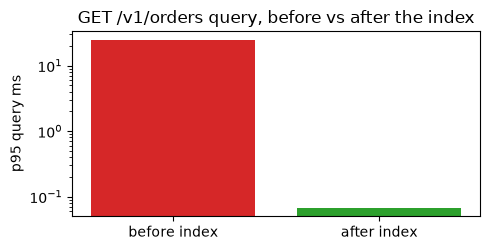

In [48]:
con.execute("CREATE INDEX idx_orders_user_created ON orders(user_id, created_at)")
print("plan now:", plan(MY_ORDERS, (42,)))
lat_after = measure_endpoint(StatStatements())
summary = pd.DataFrame({"p50 ms": [np.percentile(lat_before, 50), np.percentile(lat_after, 50)],
                        "p95 ms": [np.percentile(lat_before, 95), np.percentile(lat_after, 95)]},
                       index=["before index", "after index"]).round(3)
print(summary.to_string()); con.close()

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.bar(summary.index, summary["p95 ms"], color=["tab:red", "tab:green"])
ax.set_ylabel("p95 query ms"); ax.set_yscale("log"); ax.set_title("GET /v1/orders query, before vs after the index")
plt.tight_layout(); plt.show()

**Step 7: follow up.** Write a short blameless postmortem (what happened, impact, timeline, root cause, what we changed). Then make it hard to repeat: a test that runs `EXPLAIN` for key queries and fails on a full scan of large tables, an alert on p95 per endpoint, and a review checklist item "new query paths come with their index".

**Other common first incidents, and the first thing to check:**

| Symptom | First check | Usual fix |
|---|---|---|
| All endpoints slow at once | DB CPU, active connections, pool wait time | smaller pools + pooler, kill a runaway query, scale the DB |
| Errors "too many clients" | connection count by client/application name | pooler, lower pool sizes, cap serverless concurrency |
| Timeouts only at peak | saturation: pool waiting, queue depth, CPU throttling | more instances, cache, rate limits, move work to jobs |
| Slow after a migration | locks (`pg_locks`, `pg_stat_activity` wait events) | `lock_timeout`, run outside peak, `CONCURRENTLY` |
| Duplicate charges or emails | idempotency keys, retry logs | idempotency keys end to end (3.6, 4.3) |
| Users see old data | cache TTLs, replica lag | invalidate on write, read-your-writes routing (1.9, 2.8) |
| LLM endpoint slow or failing | provider latency/error rate, your rate limiter, token counts | timeouts + fallbacks, queue + 202, smaller prompts |

## 7. Service map, try it for real, certification topic map

### 7.1 Service map: same need, three clouds

As of late 2026; product names change, so check the providers' docs.

| Need | AWS | Azure | Google Cloud | Cloud-neutral / other |
|---|---|---|---|---|
| Managed PostgreSQL | Amazon RDS for PostgreSQL, Aurora PostgreSQL | Azure Database for PostgreSQL (flexible server) | Cloud SQL for PostgreSQL, AlloyDB | Neon, Supabase, Crunchy Bridge |
| Connection pooling | RDS Proxy | built-in PgBouncer (flexible server) | Cloud SQL managed connection pooling; PgBouncer on GKE | PgBouncer, Neon/Supabase poolers |
| Query insights | CloudWatch Database Insights / Performance Insights | Query Store, Query Performance Insight | Cloud SQL Query Insights | `pg_stat_statements`, pganalyze |
| Cache | ElastiCache (Valkey / Redis OSS), MemoryDB | Azure Managed Redis | Memorystore (Valkey / Redis) | Redis Cloud, Upstash |
| Task queue | SQS (+ Lambda or workers) | Service Bus, Queue Storage | Cloud Tasks, Pub/Sub | Celery/RQ/Arq on Redis or RabbitMQ |
| Scheduler | EventBridge Scheduler | Functions timer trigger, Logic Apps | Cloud Scheduler | Kubernetes CronJob, `pg_cron` |
| Workflows | Step Functions | Durable Functions, Logic Apps | Workflows | Temporal |
| Object storage | S3 | Blob Storage | Cloud Storage | Cloudflare R2, MinIO |
| CDN / HTTP cache | CloudFront | Azure Front Door | Cloud CDN | Cloudflare, Fastly |
| API gateway / rate limits | API Gateway | API Management | API Gateway, Apigee | Kong, Envoy |
| Email | SES | Azure Communication Services Email | (no first-party transactional email; use a partner) | Postmark, SendGrid, Resend |
| Logs / metrics / traces | CloudWatch, X-Ray | Azure Monitor, Application Insights | Cloud Logging, Monitoring, Trace | OpenTelemetry + Grafana stack, Datadog |
| Secrets | Secrets Manager, Parameter Store | Key Vault | Secret Manager | HashiCorp Vault, Infisical |

### 7.2 How to try it for real (free and local)

Everything here runs on a laptop with Docker; none of it is needed for this notebook.

```bash
# PostgreSQL 18 + PgBouncer locally
docker network create pgnet
docker run -d --name pg --network pgnet -e POSTGRES_PASSWORD=pw -p 5432:5432 postgres:18 \
  -c shared_preload_libraries=pg_stat_statements -c log_min_duration_statement=100ms
docker run -d --name pgbouncer --network pgnet -p 6432:6432 \
  -e DATABASE_URL="postgres://postgres:pw@pg:5432/postgres" -e POOL_MODE=transaction \
  edoburu/pgbouncer        # a popular community image; check its README for current env var names
psql "postgresql://postgres:pw@localhost:6432/postgres" -c "SHOW pool_mode;"   # through the pooler

# Load test an endpoint and watch pool behaviour
pip install locust   # or: k6, hey, oha
```

1. Build a FastAPI app with SQLAlchemy and `asyncpg` against the local Postgres; add an endpoint with an N+1, find it with `pg_stat_statements`, fix it with `selectinload`.
2. Run a load test with pool sizes 2, 5, 20, 100 and plot p95 like section 2.1.
3. Point the app at PgBouncer in transaction mode and see which features break (`SET`, `LISTEN`).
4. Add Redis (`docker run -p 6379:6379 valkey/valkey`) for cache-aside and an Arq or RQ worker with retries.
5. Try Neon's or Supabase's free tier to see pooled vs direct connection strings (free-tier details in [16_Deployment/07](../16_Deployment/07_free_tier_deployment_frontend_backend_and_database.ipynb)).
6. Run `kind` (Kubernetes in Docker), deploy the app with probes and a `preStop` sleep, and roll it while a load test runs: count failed requests with and without graceful shutdown.

### 7.3 Certification topic map

These topics appear, in general form, in several cloud and database exam blueprints. Exact objectives change; check the current exam guide.

| Exam area (named generally) | Sections here |
|---|---|
| Cloud developer associate exams (AWS / Azure / Google): caching, queues, retries, idempotency, API design, observability | 1, 3, 4, 5 |
| Cloud solutions architect exams: read replicas, backups and PITR, RPO/RTO, connection proxies, CDN caching | 1.8, 2.1, 2.8, 2.11, 7.1 |
| Cloud database specialty / professional exams: performance insights, pooling, partitioning, migrations, high availability | 2 |
| Kubernetes application developer (CKAD-style): probes, graceful termination, config via env, CronJobs | 4.4, 5.1-5.3 |
| PostgreSQL associate/professional certifications: `EXPLAIN`, indexes, isolation, `pg_stat_statements`, PITR | 1.2-1.5, 2.3-2.11 |

## 8. Recap

| Topic | Remember this |
|---|---|
| Buffer pool + OS cache | second query is faster because pages are in RAM; `shared_buffers` ~25% of RAM to start; read fewer pages first |
| Plan cache | parameterized queries; prepared statements are per session (pooler caveat) |
| Materialized views | fast reads, stale until refreshed; `REFRESH ... CONCURRENTLY` needs a unique index |
| Cache-aside | TTL on every key, versioned keys, invalidate on write, decide acceptable staleness |
| HTTP caching | `ETag` + 304; `private, no-cache` for user data; `no-store` for secrets and streams |
| Connection pooling | few active connections (about 2x cores); pooler for many clients; pooled URL for apps, direct for migrations |
| PgBouncer modes | session = all features; transaction = scalable but no session state |
| N+1 | JOIN, `IN` batch (`selectinload`), DataLoader; assert query counts in tests |
| EXPLAIN | Seq Scan + big "Rows Removed by Filter" = missing index; estimates vs actuals |
| pg_stat_statements | sort by total time; high `calls` = N+1 |
| Pagination | keyset for deep/stable paging; opaque signed cursors |
| Writes | batch in one transaction; `COPY` for bulk |
| Lost update | atomic `UPDATE`, `FOR UPDATE`, or version column / `If-Match` |
| Replicas | async lag; read-your-writes via primary pinning or LSN check |
| Migrations | expand/contract; `lock_timeout`; `CONCURRENTLY`; `NOT VALID` then `VALIDATE` |
| Backups | PITR = base backup + WAL; test restores |
| Errors | RFC 9457 problem+json with request id |
| Idempotency keys | replay same key; 409 in progress; 422 different body |
| Rate limits | 429 + `Retry-After`; `RateLimit` / `RateLimit-Policy` (IETF draft) |
| Deadlines | pass remaining time down; fail fast |
| Webhooks | HMAC sign id.timestamp.body; retry with backoff; dedupe by id |
| Long-running work | 202 + operation resource; poll, webhook or SSE |
| SSE for LLMs | no buffering, no compression, heartbeats, cancel on disconnect |
| Background jobs | at-least-once + idempotent = effectively once; backoff + DLQ; outbox |
| Health checks | liveness = process; readiness = can serve now; startup = finished booting |
| Graceful shutdown | SIGTERM -> not ready -> drain -> close -> exit before SIGKILL |
| Retries | one layer, jitter, budget; circuit breakers for hard failures |
| Logs | JSON + request id via `contextvars`; copy context into threads |
| Data hygiene | UTC `timestamptz`, integer cents / `numeric`, UTF-8 + NFC |

## Interview questions

1. **Why is the second run of the same query faster?** The pages it needed are now in memory: PostgreSQL's `shared_buffers` and the OS page cache. The first run had to read them from disk. `EXPLAIN (ANALYZE, BUFFERS)` shows `hit` vs `read`.
2. **Your serverless app gets "too many clients already" during a spike. What do you do?** Each function instance opens its own connection. Use a pooled connection string (PgBouncer in transaction mode, RDS Proxy or the provider's pooler), one connection per instance, cap concurrency, and keep direct connections for migrations only.
3. **What breaks in PgBouncer transaction mode?** Session state: `SET`, `LISTEN`, SQL-level `PREPARE`, session advisory locks, `WITH HOLD` cursors, temp tables across transactions. Protocol-level prepared statements work in PgBouncer 1.21+ with `max_prepared_statements` set.
4. **What is N+1 and how do you detect it?** One query for a list plus one per item. Detect by counting queries per request in tests, or by a statement with huge `calls` in `pg_stat_statements`. Fix with JOIN, `IN` batching or a DataLoader.
5. **Why is `OFFSET` pagination slow, and what replaces it?** The database must read and discard all skipped rows, and results shift when rows are inserted. Keyset pagination with `WHERE (sort_col, id) < (:v, :id)` and an index costs the same on every page.
6. **Two requests withdraw from the same balance at once. How do you avoid a lost update?** Atomic `UPDATE ... SET balance = balance - x WHERE balance >= x`, or `SELECT ... FOR UPDATE`, or optimistic locking with a version column and retry. Over HTTP, `ETag` + `If-Match` gives the same protection.
7. **How do idempotency keys work?** The client sends a unique key per logical operation; the server stores the response under it, replays it on retries, returns 409 while the first request is still running and 422 if the same key comes with a different body.
8. **Liveness vs readiness?** Liveness failing restarts the container, so it should only check the process itself. Readiness failing removes the instance from the load balancer; it checks dependencies cheaply and fails during draining.
9. **How do you shut down gracefully on Kubernetes?** On SIGTERM: fail readiness, wait briefly for endpoint removal (often a `preStop` sleep), stop accepting new work, let in-flight requests finish, close pools, exit, all within `terminationGracePeriodSeconds` (default 30 s) before SIGKILL.
10. **Why can retries cause outages, and what limits them?** Retries multiply load on an already failing dependency (3 layers x 3 retries = 64x). Retry at one layer, only for transient errors, with exponential backoff and jitter, a retry budget and circuit breakers.
11. **Is exactly-once delivery possible?** Not in general across a network. Build at-least-once delivery with idempotent consumers (and an outbox for publishing events), which gives exactly-once *effects*.
12. **How would you design a "process this PDF" endpoint?** `POST` with an idempotency key stores the job and returns 202 + an operation URL; a worker processes it with retries and a DLQ; the client polls (or gets a webhook / SSE progress); the file itself goes to object storage via a presigned URL.

## Further reading

- PostgreSQL 18 documentation: resource settings (`shared_buffers`, `work_mem`) https://www.postgresql.org/docs/current/runtime-config-resource.html, connections https://www.postgresql.org/docs/current/runtime-config-connection.html, `PREPARE` https://www.postgresql.org/docs/current/sql-prepare.html, materialized views https://www.postgresql.org/docs/current/sql-refreshmaterializedview.html, `pg_stat_statements` https://www.postgresql.org/docs/current/pgstatstatements.html, logging https://www.postgresql.org/docs/current/runtime-config-logging.html, isolation https://www.postgresql.org/docs/current/transaction-iso.html, `SELECT ... FOR UPDATE / SKIP LOCKED` https://www.postgresql.org/docs/current/sql-select.html, continuous archiving and PITR https://www.postgresql.org/docs/current/continuous-archiving.html
- PostgreSQL wiki, "Number Of Database Connections": https://wiki.postgresql.org/wiki/Number_Of_Database_Connections
- PgBouncer features and configuration: https://www.pgbouncer.org/features.html and https://www.pgbouncer.org/config.html
- Neon connection pooling: https://neon.com/docs/connect/connection-pooling ; Supabase connecting to Postgres: https://supabase.com/docs/guides/database/connecting-to-postgres
- RFC 9110, HTTP Semantics: https://www.rfc-editor.org/rfc/rfc9110.html ; RFC 9457, Problem Details for HTTP APIs: https://www.rfc-editor.org/rfc/rfc9457.html ; RFC 6585 (428, 429): https://www.rfc-editor.org/rfc/rfc6585.html
- IETF drafts: RateLimit header fields https://datatracker.ietf.org/doc/draft-ietf-httpapi-ratelimit-headers/ and the Idempotency-Key header https://datatracker.ietf.org/doc/draft-ietf-httpapi-idempotency-key-header/
- Stripe API, idempotent requests: https://docs.stripe.com/api/idempotent_requests
- Google API Improvement Proposals: pagination AIP-158 https://google.aip.dev/158 and long-running operations AIP-151 https://google.aip.dev/151
- Standard Webhooks specification: https://github.com/standard-webhooks/standard-webhooks/blob/main/spec/standard-webhooks.md
- Celery task guide (retries, idempotency, `acks_late`): https://docs.celeryq.dev/en/stable/userguide/tasks.html
- Kubernetes probes https://kubernetes.io/docs/concepts/configuration/liveness-readiness-startup-probes/ and pod termination https://kubernetes.io/docs/concepts/workloads/pods/pod-lifecycle/
- W3C Trace Context: https://www.w3.org/TR/trace-context/ ; OpenTelemetry traces: https://opentelemetry.io/docs/concepts/signals/traces/
- The Twelve-Factor App, config: https://12factor.net/config

In [49]:
# Clean up the temporary databases
import shutil
shutil.rmtree(WORKDIR, ignore_errors=True)
print("removed", WORKDIR)

removed /tmp/prod_backend_7y18nhif
